## 1.2 MATHEMATICAL PREREQUISITES

We are going to discuss Maths here, everything that is going to be relevant for us when we make our library. We make a list of mathematical topics we are going to discuss and then beside that the methods where they are going to show up when we make the library.

We will do them in sections. The first section will contain the math needed for the `process.py` later of the library and that is the main modelling layer and the hardest one too from a coding pov. Then in next section we will cover the maths for `measure.py` layer. The point of doing this in parts is to make sure you see only the relevant math topics needed for that section.

## 1.2.1 Math for `process.py`

The list of topics we will see in this subsection are:

1. Correlated 2D Gaussian increments and Cholesky Factorization. (`_vol`, `_gauss_paths`, `_bvn`)
2. Independence & Product Measure. (`pdf` in `Process`)
3. Moment Generating Function (MGF) & Cumulant Generating Function. (`has_mgf`, `cumulant`, `theta_domain`)
4. The Esscher Transform / Exponential Tilting. (`esscher`, `esscher_space`, `at`)
5. Lévy Processes & Stationary, Independent increments. (`is_levy`, `levy_state`)
6. Radon-Nikodym reweighting. (`weights` in class `Process` and `stocks`)
7. Margrabe's Exchange Option Formula & Numeraire Pricing. (`exchange_option`)
    
Let us start with these one by one now.

1. **Constructing the Volatility Matrix $A$** (`_vol`)
      
   Given coordinate volatilities $\sigma = (\sigma_1, \sigma_2)^T$ and correlation $\rho \in (-1, 1)$:
   $$L = \begin{pmatrix} 1 & 0 \\ \rho & \sqrt{1 - \rho^2} \end{pmatrix}, \qquad A = \operatorname{diag}(\sigma) L = \begin{pmatrix} \sigma_1 & 0 \\ \sigma_2 \rho & \sigma_2 \sqrt{1 - \rho^2} \end{pmatrix}$$
This is the Cholesky decomposition of the instantaneous covariance matrix $\Sigma$:
   $$\Sigma = A A^\top = \begin{pmatrix} \sigma_1^2 & \rho \sigma_1 \sigma_2 \\ \rho \sigma_1 \sigma_2 & \sigma_2^2 \end{pmatrix}$$   Why do this? If $Z \sim \mathcal{N}(0, I_2)$ is a vector of two independent standard normals, then $A Z \sim \mathcal{N}(0, \Sigma)$. Notice that $\operatorname{Var}((AZ)_1) = \sigma_1^2$, $\operatorname{Var}((AZ)_2) = \sigma_2^2(\rho^2 + 1 - \rho^2) = \sigma_2^2$, and $\operatorname{Cov}((AZ)_1, (AZ)_2) = \rho \sigma_1 \sigma_2$.

   Bivariate Normal Density (`_bvn_pdf`)

   For any 2-D Gaussian vector $X \sim \mathcal{N}(m, \Sigma)$, let $\Delta x = x - m_1$ and $\Delta y = y - m_2$. The determinant of $\Sigma$ is $\det(\Sigma) = \Sigma_{11}\Sigma_{22} - \Sigma_{12}^2$, and the inverse is:
   $$\Sigma^{-1} = \frac{1}{\det(\Sigma)} \begin{pmatrix} \Sigma_{22} & -\Sigma_{12} \\ -\Sigma_{12} & \Sigma_{11} \end{pmatrix}$$
Expanding the quadratic form $q = (x - m)^\top \Sigma^{-1} (x - m)$ gives:
   $$q = \frac{\Sigma_{22}(\Delta x)^2 - 2\Sigma_{12}\Delta x \Delta y + \Sigma_{11}(\Delta y)^2}{\det(\Sigma)}$$
Plugging this into the multivariate normal density formula yields _bvn_pdf:
   $$f(x, y) = \frac{1}{2\pi \sqrt{\det(\Sigma)}} \exp\left(-\frac{1}{2} q\right)$$
When we later code these we stick to these same notations of "q", "$\mu$" etc.

2. **Independence & Product Measure** (`pdf` in `Process`)

   The default settings for us is going to be that the coordinates are independent and hence the default density function definition for us is going to be $$f_{X_t, Y_t}(x,y) = f_{X_t}(x) f_{Y_t}(y)$$
When the process $\{(X_t, Y_t)\}$ do not have independent coordinates we will customize it. But even when they do split up, there are some problems such as $\bullet$ "what happens to the density function at time $0$, it should be a dirac-delta function since the process starts at  a fixed point and hence has point mass!?" $\bullet$ "is the process continuous or discrete!?"

We can code and ensure the density function's method to return `None` for the `time=0` and for `time<0` too as a matter of fact. Under default settings of independence, we will look at the joint pdf as product of coordinate pdfs and the coordinate pdfs can be easily calculated using `scipy.stats`. More precisely, `scipy.stats.rv_continuous` for continuous coordinate such as `cauchy`, `normal` etc calculates pdf using the formulae $f_k(c) = \frac{d}{dc} \mathbb{P}(X_{k,t} \le c)$ (k is the coordinate 1 or 2). Similarly, `scipy.stats.rv_discrete` does it for discrete ones such as `poisson` using the formulae $p_k(n) = \mathbb{P}(X_{k,t} = n)$ (naturally we have to use the probability mass function instead of the pdf).

In the above mentioned problems the hard work is basically outsourced and `scipy.stats` handles it. The problem of coordinates not being independent is something we will handle ourselves. We will have these scenarios when we have `bm` (this is the class for Brownian motion) and `stocks` (well, this is the class for the stocks) with `rho`$\neq 0$ (correlation exists). Basically we will do the evaluations ourselves. That is exactly what we did above in the discussion about the volatility matrix A. For `bm`, we use that directly and for `stocks` we will turn it into log-stocks which is a `bm` and then use volatility matrix again. Let's see the math behind `stocks` a bit more closely. Again the notations used here will be more or less same to the codes we have later. We will use `lx` and `ly` etc for $l_x$ and $l_y$. 

For stock prices, $(S_{1,t}, S_{2,t})$ is not bivariate normal—it is bivariate log-normal. Because $S_{k,t} = s_k \exp(B_{k,t})$ where Brownian motion $B_t = (B_{1,t}, B_{2,t})^T \sim \mathcal{N}(m_{\log} t,\; \Sigma t)$ with $m_{\log} = \mu - r - \frac{1}{2}\operatorname{diag}(\Sigma)$, we find the joint density of $(S_{1,t}, S_{2,t})$ using the 2-D Change of Variables (Jacobian) Theorem.   In `stocks.pdf(self, t, x, y, start=None)` (when we do make it later), we execute these four exact steps:   
(i) Enforce Positive Support ($x > 0, y > 0$):
Stock prices live strictly on $(0, \infty)^2$. The code creates a boolean mask `ok = (x > 0) & (y > 0)` and replaces any non-positive grid points with 1.0 temporarily (done by codes `np.where(ok, x, 1.0)`) so `np.log` never throws `NaN` or `-inf` warnings on grid boundaries.   
(ii) Invert the Transformation to Log-Space:
We map the price coordinates $(x, y)$ back to the underlying Gaussian log-increments $(l_x, l_y)$:
$$l_x = \ln\left(\frac{x}{s_1}\right), \qquad l_y = \ln\left(\frac{y}{s_2}\right)$$
They will be coded as:
```text
ok = (x > 0) & (y > 0)
    lx, ly = np.log(np.where(ok, x, 1.0) / s[0]), np.log(np.where(ok, y, 1.0) / s[1])
```
By the multivariate change-of-variables formula, if $(L_1, L_2) = (\ln(S_1/s_1), \ln(S_2/s_2))$, then:$$f_{S_1, S_2}(x, y) = f_{L_1, L_2}(l_x, l_y) \cdot \left\vert{}\det \frac{\partial (l_x, l_y)}{\partial (x, y)}\right\vert{}$$Since $l_x$ depends only on $x$ and $l_y$ depends only on $y$, the Jacobian matrix is diagonal:$$J = \begin{pmatrix} \frac{\partial l_x}{\partial x} & \frac{\partial l_x}{\partial y} \\ \frac{\partial l_y}{\partial x} & \frac{\partial l_y}{\partial y} \end{pmatrix} = \begin{pmatrix} \frac{1}{x} & 0 \\ 0 & \frac{1}{y} \end{pmatrix} \implies \vert{}\det(J)\vert{} = \frac{1}{xy}$$
This is why `stocks.pdf` will divide `_bvn_pdf` by `x * y`
```text
p = _bvn_pdf(lx, ly, self.log_drift * t, self.Sigma * t) / (np.where(ok, x, 1.0) * np.where(ok, y, 1.0))
```

3. **Moment Generating Function (MGF) & Cumulant Generating Function.** (`has_mgf`, `cumulant`, `theta_domain`)
   
    We know for $\theta \in \mathbb{R}^2$,$$\phi_X(\theta) := \mathbb{E}\big[e^{i \theta \cdot X}\big] = \int_{\mathbb{R}^d} e^{i \theta \cdot x} \, \mathbb{P}_X(dx)$$$$M_X(\theta) := \mathbb{E}\big[e^{\theta \cdot X}\big] = \int_{\mathbb{R}^d} e^{\theta \cdot x} \, \mathbb{P}_X(dx)$$

are Characteristic Function & Moment Generating function respectively. Unlike $\phi$, $M$ can be $\infty$. In the convex domain $\mathcal{D} = \{\theta \in \mathbb{R}^d : M_X(\theta) < \infty\}$ containing $0$, we define the Cumulant Generating Function$$\kappa_X(\theta) := \ln M_X(\theta) = \ln \mathbb{E}\big[e^{\theta \cdot X}\big]$$By stationary and independent increments imply that the characteristic function (and, when it exists, the moment generating function) have the property$$\phi_{t+s}(\theta)=\phi_t(\theta)\phi_s(\theta)$$$$M_{t+s}(\theta)=M_t(\theta)M_s(\theta)$$$$ie,\quad \kappa_{t+s}(\theta) = \kappa_t(\theta) + \kappa_s(\theta)$$So by linearity of $\kappa$ we have $\kappa_t = t\,\kappa_1$. Use $\kappa_1 = \kappa$. Now by definition of cumulant,$$\mathbb{E}\big[e^{\theta \cdot Y_t}\big] = e^{t \, \kappa(\theta)}$$This linear-in-$t$ scaling is why a single constant tilt parameter $\theta$ defines a consistent Radon–Nikodym martingale $Z_t = \exp(\theta \cdot Y_t - t\kappa(\theta))$ across all time slices simultaneously. Note that, when the process do not have stationary increment or independent increment, we fail to get the linearity of $\kappa_t$ and hence the entire argument falls short. We will see later that when a process is not Levy, one of these properties fail (provided it is a continuous process). Let us see this Martingale property a bit closely before moving on. This leads us to one of the most important topics for this library called *Esscher's tilt*.

Let $(\mathcal{F}_t)_{t \ge 0}$ be the natural filtration generated by the $\mathbb{R}^2$-valued Lévy process $Y = (Y^{(1)}, Y^{(2)})$, where $\mathcal{F}_t = \sigma(Y_s : 0 \le s \le t)$. Assume $\theta = (\theta_1, \theta_2) \in \mathbb{R}^2$ is fixed in the domain where the cumulant generating function satisfies$$\kappa(\theta) = \ln \mathbb{E}\big[e^{\theta \cdot Y_t}\big] = \ln \mathbb{E}\big[e^{\theta_1 Y_1^{(1)} + \theta_2 Y_1^{(2)}}\big] < \infty.$$

4. **The Esscher Transform / Exponential Tilting.** (`esscher`, `esscher_space`, `at`)

   **Definition (Esscher transform) :** The process $(Z_t)_{t \ge 0}$ (also called the exponential tilting process) forms a true $(\mathcal{F}_t, \mathbb{P})$-martingale and is defined as $$Z_t := \exp\big(\theta \cdot Y_t - t\,\kappa(\theta)\big) = \frac{e^{\theta \cdot Y_t}}{\mathbb{E}\big[e^{\theta \cdot Y_t}\big]}$$
To verify that $(Z_t)_{t \ge 0}$ is a true $(\mathcal{F}_t, \mathbb{P})$-martingale:

Adaptedness: Since $Y_t = (Y_t^{(1)}, Y_t^{(2)}) \in \mathbb{R}^2$ is $\mathcal{F}_t$-measurable and the map $((y_1, y_2), t) \mapsto \exp(\theta_1 y_1 + \theta_2 y_2 - t\kappa(\theta))$ is continuous on $\mathbb{R}^2 \times [0, \infty)$, $Z_t$ is $\mathcal{F}_t$-measurable.

Integrability ($L^1$): Since $Z_t > 0$ everywhere:$$\mathbb{E}[\lvert Z_t \rvert] = \mathbb{E}[Z_t] = e^{-t\kappa(\theta)} \mathbb{E}\big[e^{\theta \cdot Y_t}\big] = e^{-t\kappa(\theta)} e^{t\kappa(\theta)} = 1 < \infty$$

Martingale Property: For any $0 \le s < t$, factor $Z_t$ into its $\mathcal{F}_s$-measurable part and its future increment in $\mathbb{R}^2$:$$Z_t = \exp\big(\theta \cdot Y_s - s\,\kappa(\theta)\big) \cdot \exp\big(\theta \cdot (Y_t - Y_s) - (t - s)\,\kappa(\theta)\big) = Z_s \cdot \exp\big(\theta \cdot (Y_t - Y_s) - (t - s)\,\kappa(\theta)\big)$$Take the conditional expectation given $\mathcal{F}_s$:$$\begin{aligned} \mathbb{E}[Z_t \mid \mathcal{F}_s] &= Z_s \, e^{-(t-s)\kappa(\theta)} \, \mathbb{E}\big[e^{\theta \cdot (Y_t - Y_s)} \mid \mathcal{F}_s\big] && \text{(since } Z_s \text{ is } \mathcal{F}_s\text{-measurable)} \\  &= Z_s \, e^{-(t-s)\kappa(\theta)} \, \mathbb{E}\big[e^{\theta \cdot (Y_t - Y_s)}\big] && \text{(since } Y_t - Y_s \perp\!\!\!\perp \mathcal{F}_s\text{)} \\  &= Z_s \, e^{-(t-s)\kappa(\theta)} \, \mathbb{E}\big[e^{\theta \cdot Y_{t-s}}\big] && \text{(by stationarity of increments)} \\  &= Z_s \, e^{-(t-s)\kappa(\theta)} \, e^{(t-s)\kappa(\theta)} && \text{(by linear-in-}t\text{ scaling)} \\  &= Z_s \end{aligned}$$

Because $Z_t > 0$ almost surely and $\mathbb{E}[Z_t] = 1$ for every $t \ge 0$, we can define a family of probability measures $(\mathbb{Q}_t)_{t \ge 0}$ on $(\Omega, \mathcal{F}_t)$ via the Radon–Nikodym derivatives:$$\frac{d\mathbb{Q}_t}{d\mathbb{P}}\bigg\vert{}_{\mathcal{F}_t} := Z_t \iff \mathbb{Q}_t(A) = \mathbb{E}^{\mathbb{P}}[Z_t \mathbf{1}_A], \quad \forall A \in \mathcal{F}_t$$Why a single constant $\theta$ makes this globally consistent?? 

Suppose $0 \le s < t$ and take an event $A \in \mathcal{F}_s$. Since $\mathcal{F}_s \subseteq \mathcal{F}_t$, $A$ is also in $\mathcal{F}_t$. Using the tower property of conditional expectation and the martingale property $\mathbb{E}^{\mathbb{P}}[Z_t \mid \mathcal{F}_s] = Z_s$:$$\mathbb{Q}_t(A) = \mathbb{E}^{\mathbb{P}}[Z_t \mathbf{1}_A] = \mathbb{E}^{\mathbb{P}}\Big[\mathbb{E}^{\mathbb{P}}[Z_t \mid \mathcal{F}_s]\,\mathbf{1}_A\Big] = \mathbb{E}^{\mathbb{P}}[Z_s \mathbf{1}_A] = \mathbb{Q}_s(A)$$

The geometry: Depending on whether we want to look at the $Z_t$ as a process or $Y_t$ under the new measure $\mathbb{Q}$, we will get two different pictures.

If we are looking at literal plot of $t \mapsto Z_t(\omega) = \exp(\theta \cdot Y_t(\omega) - t\kappa(\theta))$ for a fixed outcome $\omega \in \Omega$, we get to see the actual "tilt" happening. But if we look at $Y_t$ under the new measure $\mathbb{Q}$, the plot will not change even a bit but instead the underlying weights have been altered. If we can colour the paths based on how much weight they have, the picture of $Y_t$ under the $\mathbb{P}$ and new measure $\mathbb{Q}$ will look very different. This is important for us because we are going to do this in 3D soon and under change of measure the colours will actually change.

Alternate justification for why this is called "exponential tilt": It is easily answered looking at the density functions. We have $$d\mathbb{Q}_t = Z_t d\mathbb{P}$$ which gives us:
$$f_t^{\mathbb{Q}}(x) = \frac{e^{\theta \cdot x}}{\mathbb{E}^{\mathbb{P}}[e^{\theta \cdot Y_t}]} f_t^{\mathbb{P}}(x) = e^{\theta \cdot x - t\kappa(\theta)} f_t^{\mathbb{P}}(x)$$
Take the logarithm of the density (the log-likelihood):$$\ln f_t^{\mathbb{Q}}(x) = \ln f_t^{\mathbb{P}}(x) + \underbrace{\theta \cdot x}_{\text{linear tilt}} - \underbrace{t\kappa(\theta)}_{\text{vertical shift to re-normalize}}$$Geometrically, in log-density space, adding $\theta \cdot x$ literally tilts the log-density surface by a hyperplane of slope $\theta$.

This will actually coincide with *Girsanov's Risk-neutral change of measure* when applied to stock prices $Y_t$.

5. **Lévy Processes & Stationary, Independent Increments** (`is_levy`, `levy_state`)
   
   In our library, the boolean flag `is_levy` and the method `levy_state(X, start)` identify which processes possess the structural properties required for uniform exponential tilting across time.

**Definition (Lévy Process):** A stochastic process $(Y_t)_{t \ge 0}$ in $\mathbb{R}^2$ is a Lévy process if it satisfies four properties:

(i) Starts at the origin: $Y_0 = 0$ almost surely.   
(ii) Independent increments: For any $0 \le t_0 < t_1 < \dots < t_m$, the increments $Y_{t_1} - Y_{t_0},\; Y_{t_2} - Y_{t_1},\; \dots,\; Y_{t_m} - Y_{t_{m-1}}$ are mutually independent.   
(iii) Stationary increments: For any $s, t \ge 0$, the distribution of $Y_{t+s} - Y_t$ depends only on the elapsed time $s$, not on $t$.   
(iv) Stochastic continuity: For every $\varepsilon > 0$ and $t \ge 0$, $\lim_{h \to 0} \mathbb{P}(\Vert{}Y_{t+h} - Y_t\Vert{} > \varepsilon) = 0$.

Classification to keep in mind:

$\bullet$ True Lévy Processes (`is_levy = True`, `levy_state = X - start`): `bm`, `poisson`, `gamma_process`, `cauchy_process`. For all of these, shifting by the initial position $W_t = V_t - V_0$ produces a true Lévy process starting at $0$, so the default `Process.levy_state(X, start)` returns `X - start`.   

$\bullet$ Geometric Lévy Process (`stocks`, `is_levy = False`, `esscher_space = "log"`): `stocks`

$\bullet$ Non-Lévy Processes (`is_levy = False`, `esscher_space = None`): `bm_bridge`, `_IID()`

Even when a process is a genuine Lévy process `(is_levy = True)`, we can only apply an exponential tilt if its Moment Generating Function (MGF) is finite in a neighborhood of the origin. Let's do the calculation of `cumulant(theta)` for few of the processes that we mentioned above and are going to be a part of this library.

We will also calculate `theta_domain(self)` returning the valid interval $(\theta_{\min}, \theta_{\max})$ where $\mathbb{E}[e^{\theta^T Y_1}] < \infty$.

$\bullet$ 2D Brownian Motion

Let $W_1 = (W_{1,1}, W_{1,2})^T \sim \mathcal{N}(0, I_2)$ be a standard $2$-dimensional Gaussian vector, and define $Y_1 = \mu + A W_1$ for a drift vector $\mu = (\mu_1, \mu_2)^T \in \mathbb{R}^2$ and matrix $A \in \mathbb{R}^{2 \times 2}$. By linear transformation of Gaussians, $Y_1 \sim \mathcal{N}(\mu, \Sigma)$ where $\Sigma = A A^T \in \mathbb{R}^{2 \times 2}$ is positive semi-definite.Assuming $\Sigma$ is positive definite ($\det \Sigma > 0$), $Y_1$ has density on $\mathbb{R}^2$:$$f(x) = \frac{1}{2\pi (\det \Sigma)^{1/2}} \exp\!\left(-\frac{1}{2}(x - \mu)^T \Sigma^{-1} (x - \mu)\right), \qquad x = (x_1, x_2)^T \in \mathbb{R}^2$$Calculating the MGF and $\kappa(\theta)$For $\theta = (\theta_1, \theta_2)^T \in \mathbb{R}^2$, we compute $\mathbb{E}[e^{\theta^T Y_1}]$ by writing $Y_1 = \mu + A W_1$ (which holds even if $\Sigma$ is singular/degenerate):$$\mathbb{E}\big[e^{\theta^T Y_1}\big] = \mathbb{E}\big[e^{\theta^T (\mu + A W_1)}\big] = e^{\theta^T \mu} \, \mathbb{E}\big[e^{(A^T \theta)^T W_1}\big]$$Let $v := A^T \theta = (v_1, v_2)^T \in \mathbb{R}^2$. Since the coordinates $W_{1,1}$ and $W_{1,2}$ are i.i.d. $\mathcal{N}(0,1)$, the expectation factorizes into two identical 1D Gaussian integrals. For a single coordinate $Z \sim \mathcal{N}(0,1)$ and scalar $v_k \in \mathbb{R}$ ($k \in \{1, 2\}$), we complete the square in the exponent:$$v_k z - \frac{1}{2} z^2 = -\frac{1}{2}\big(z^2 - 2 v_k z + v_k^2\big) + \frac{1}{2} v_k^2 = -\frac{1}{2}(z - v_k)^2 + \frac{1}{2} v_k^2$$Integrating over $z \in \mathbb{R}$:$$\mathbb{E}\big[e^{v_k Z}\big] = \int_{-\infty}^{\infty} \frac{1}{\sqrt{2\pi}} e^{v_k z - \frac{1}{2}z^2}\,dz = e^{\frac{1}{2}v_k^2} \underbrace{\int_{-\infty}^{\infty} \frac{1}{\sqrt{2\pi}} e^{-\frac{1}{2}(z - v_k)^2}\,dz}_{=\,1 \text{ (density of } \mathcal{N}(v_k, 1)\text{)}} = e^{\frac{1}{2}v_k^2}$$Multiplying across $k = 1, 2$:$$\mathbb{E}\big[e^{v^T W_1}\big] = e^{\frac{1}{2}v_1^2} \cdot e^{\frac{1}{2}v_2^2} = \exp\!\left(\frac{1}{2} v^T v\right) = \exp\!\left(\frac{1}{2} (A^T \theta)^T (A^T \theta)\right) = \exp\!\left(\frac{1}{2} \theta^T A A^T \theta\right) = \exp\!\left(\frac{1}{2} \theta^T \Sigma \theta\right)$$Combining with the $e^{\mu^T \theta}$ prefactor and taking the natural logarithm:$$\mathbb{E}\big[e^{\theta^T Y_1}\big] = \exp\!\left(\mu^T \theta + \frac{1}{2}\theta^T \Sigma \theta\right) \implies \kappa(\theta) = \mu^T \theta + \frac{1}{2}\theta^T \Sigma \theta$$Domain: For any $\theta \in \mathbb{R}^2$, the quadratic term $-\frac{1}{2}z^2$ dominates the linear term $v_k z$ as $\vert{}z\vert{} \to \infty$, so both integrals converge everywhere. Thus $\mathcal{D}_\kappa = \mathbb{R}^2$ (i.e., $(-\infty, \infty)$ per coordinate).Effect of Tilting ($\mathbb{Q}$): $\kappa^{\mathbb{Q}}(\eta) = \kappa(\theta + \eta) - \kappa(\theta) = (\mu + \Sigma \theta)^T \eta + \frac{1}{2}\eta^T \Sigma \eta$. Tilting shifts the drift vector from $\mu$ to $\mu + \Sigma \theta$ while leaving the $2 \times 2$ covariance matrix $\Sigma$ unchanged.

$\bullet$ 2D Discounted Stocks (stocks)
    
Under the physical measure $\mathbb{P}$, a 2-asset Geometric Brownian Motion $S_t = (S_{1,t}, S_{2,t})^T$ with drift vector $\mu = (\mu_1, \mu_2)^T$, $2 \times 2$ diffusion matrix $A$ ($\Sigma = A A^T$), and risk-free rate $r$ solves:$$dS_{k,t} = \mu_k S_{k,t}\,dt + S_{k,t} (A\,dW_t)_k, \qquad k \in \{1, 2\}$$Define the discounted stock price $\tilde{S}_{k,t} := e^{-rt} S_{k,t}$. By Itô's lemma applied to $\ln \tilde{S}_{k,t} = \ln S_{k,t} - rt$:$$d(\ln \tilde{S}_{k,t}) = \frac{dS_{k,t}}{S_{k,t}} - r\,dt - \frac{1}{2}\frac{d\langle S_k \rangle_t}{S_{k,t}^2} = \left(\mu_k - r - \frac{1}{2}\Sigma_{kk}\right)dt + (A\,dW_t)_k$$where $\Sigma_{kk} = (A A^T)_{kk} = A_{k1}^2 + A_{k2}^2$ is the $k$-th diagonal entry of $\Sigma$.Integrating from $t = 0$ to $t = 1$ gives the 2D Lévy log-return increment:$$Y_1 := \ln\!\left(\frac{\tilde{S}_1}{\tilde{S}_0}\right) = m_{\log} + A W_1 \sim \mathcal{N}(m_{\log}, \Sigma), \qquad m_{\log} := \begin{pmatrix} \mu_1 - r - \frac{1}{2}\Sigma_{11} \\ \mu_2 - r - \frac{1}{2}\Sigma_{22} \end{pmatrix} = \mu - r\mathbf{1} - \frac{1}{2}\operatorname{diag}(\Sigma)$$Calculating $\kappa(\theta)$ & Risk-Neutral ConditionBecause $Y_1$ has the exact same 2D Gaussian structure as bm with $\mu$ replaced by $m_{\log}$, the calculation is identical:$$\kappa(\theta) = m_{\log}^T \theta + \frac{1}{2}\theta^T \Sigma \theta, \qquad \text{Domain: } (-\infty, \infty) \text{ per coordinate } (\mathbb{R}^2)$$Connection to Risk-Neutral Pricing: Under the tilted measure $\mathbb{Q}$, the log-return drift becomes $m_{\log}^{\mathbb{Q}} = m_{\log} + \Sigma\theta$. For $\tilde{S}_t$ to be a 2D $\mathbb{Q}$-martingale, its log-return drift must equal $-\frac{1}{2}\operatorname{diag}(\Sigma)$ (so that $\mathbb{E}^{\mathbb{Q}}[\tilde{S}_{k,1}/\tilde{S}_{k,0}] = \exp(m_{\log,k}^{\mathbb{Q}} + \frac{1}{2}\Sigma_{kk}) = 1$ for $k = 1, 2$). Setting $m_{\log} + \Sigma\theta = -\frac{1}{2}\operatorname{diag}(\Sigma)$ gives $\Sigma\theta = -(\mu - r\mathbf{1})$, recovering the 2-asset market price of risk equation.
     
$\bullet$ 2D Independent Poisson Process (poisson)
     
Let $Y_t = (Y_{1,t}, Y_{2,t})^T \in \mathbb{R}^2$ where $Y_{1,t}$ and $Y_{2,t}$ are independent Poisson processes with intensities $\lambda_1, \lambda_2 > 0$. At $t = 1$, $Y_{k,1} \sim \operatorname{Poisson}(\lambda_k)$ has probability mass function:$$\mathbb{P}(Y_{k,1} = n) = \frac{\lambda_k^n e^{-\lambda_k}}{n!}, \qquad n \in \{0, 1, 2, \dots\}, \quad k \in \{1, 2\}$$Calculating the MGF and $\kappa(\theta)$For a single coordinate $k \in \{1, 2\}$ and $\theta_k \in \mathbb{R}$:$$\begin{aligned} \mathbb{E}\big[e^{\theta_k Y_{k,1}}\big] &= \sum_{n=0}^{\infty} e^{\theta_k n} \frac{\lambda_k^n e^{-\lambda_k}}{n!} \\ &= e^{-\lambda_k} \sum_{n=0}^{\infty} \frac{(\lambda_k e^{\theta_k})^n}{n!} && \text{(combine } e^{\theta_k n} \lambda_k^n = (\lambda_k e^{\theta_k})^n\text{)} \\ &= e^{-\lambda_k} \cdot e^{\lambda_k e^{\theta_k}} && \text{(since } \sum_{n=0}^\infty \frac{x^n}{n!} = e^x \text{ for all } x \in \mathbb{R}\text{)} \\ &= \exp\!\big(\lambda_k(e^{\theta_k} - 1)\big) \end{aligned}$$Since $Y_{1,1}$ and $Y_{2,1}$ are independent, the joint MGF for $\theta = (\theta_1, \theta_2)^T \in \mathbb{R}^2$ is the product of the marginal MGFs:$$\mathbb{E}\big[e^{\theta^T Y_1}\big] = \mathbb{E}\big[e^{\theta_1 Y_{1,1}}\big]\,\mathbb{E}\big[e^{\theta_2 Y_{2,1}}\big] = \exp\!\big(\lambda_1(e^{\theta_1} - 1)\big) \exp\!\big(\lambda_2(e^{\theta_2} - 1)\big)$$Taking the natural logarithm yields $\kappa(\theta)$:$$\kappa(\theta) = \sum_{k=1}^{2} \lambda_k\big(e^{\theta_k} - 1\big)$$Domain: The Taylor series for $e^x$ converges everywhere on $\mathbb{R}$ (the $n!$ in the denominator grows super-exponentially, crushing $(\lambda_k e^{\theta_k})^n$ for any $\theta_k \in \mathbb{R}$). Thus $\mathcal{D}_\kappa = \mathbb{R}^2$.Effect of Tilting ($\mathbb{Q}$): $\kappa^{\mathbb{Q}}(\eta) = \kappa(\theta + \eta) - \kappa(\theta) = \sum_{k=1}^2 \lambda_k e^{\theta_k}(e^{\eta_k} - 1)$. Tilting scales the Poisson jump intensity in each coordinate from $\lambda_k$ to $\lambda_k^{\mathbb{Q}} = \lambda_k e^{\theta_k}$.

$\bullet$ 2D Independent Gamma Process (gamma_process)
     
A 2D Gamma process is a pure-jump subordinator taking values in $\mathbb{R}_+^2$. Let $Y_{1,1}$ and $Y_{2,1}$ be independent with $Y_{k,1} \sim \operatorname{Gamma}(\text{shape}=a_k, \text{rate}=b_k)$ where $a_k, b_k > 0$ ($k \in \{1, 2\}$). Its density on $(0, \infty)$ is:$$f_k(x) = \frac{b_k^{a_k}}{\Gamma(a_k)} x^{a_k - 1} e^{-b_k x}, \qquad x > 0$$where $\Gamma(a_k) = \int_0^\infty u^{a_k - 1} e^{-u}\,du$ is the Gamma function.Calculating the MGF and $\kappa(\theta)$For coordinate $k \in \{1, 2\}$, we compute:$$\mathbb{E}\big[e^{\theta_k Y_{k,1}}\big] = \int_0^\infty e^{\theta_k x} \frac{b_k^{a_k}}{\Gamma(a_k)} x^{a_k - 1} e^{-b_k x}\,dx = \frac{b_k^{a_k}}{\Gamma(a_k)} \int_0^\infty x^{a_k - 1} e^{-(b_k - \theta_k)x}\,dx$$Convergence check: Near $x = 0^+$, $x^{a_k - 1}$ is integrable because $a_k > 0$. As $x \to +\infty$, the exponential factor $e^{-(b_k - \theta_k)x}$ decays to $0$ if and only if $b_k - \theta_k > 0$, i.e., $\theta_k < b_k$. If $\theta_k \ge b_k$, the integrand grows or behaves as $x^{a_k - 1}$ at infinity and the integral diverges to $+\infty$.Assuming $\theta_k < b_k$, perform the substitution $u = (b_k - \theta_k)x$, so $x = \frac{u}{b_k - \theta_k}$ and $dx = \frac{du}{b_k - \theta_k}$:$$\begin{aligned} \mathbb{E}\big[e^{\theta_k Y_{k,1}}\big] &= \frac{b_k^{a_k}}{\Gamma(a_k)} \int_0^\infty \left(\frac{u}{b_k - \theta_k}\right)^{a_k - 1} e^{-u} \frac{du}{b_k - \theta_k} \\ &= \frac{b_k^{a_k}}{(b_k - \theta_k)^{a_k}} \cdot \frac{1}{\Gamma(a_k)} \underbrace{\int_0^\infty u^{a_k - 1} e^{-u}\,du}_{=\,\Gamma(a_k)} \\ &= \left(\frac{b_k}{b_k - \theta_k}\right)^{a_k} = \left(1 - \frac{\theta_k}{b_k}\right)^{-a_k} \end{aligned}$$Multiplying over the two independent coordinates for $\theta = (\theta_1, \theta_2)^T$ and taking the natural logarithm:$$\kappa(\theta) = \ln \prod_{k=1}^{2} \left(1 - \frac{\theta_k}{b_k}\right)^{-a_k} = -\sum_{k=1}^{2} a_k \ln\!\left(1 - \frac{\theta_k}{b_k}\right)$$Domain & Numerical Safety Buffer: The exact mathematical domain is $(-\infty, b_1) \times (-\infty, b_2)$ (or $(-\infty, \min(b_1, b_2))$ for a shared scalar bound). As $\theta_k \uparrow b_k$, $\kappa(\theta) \to +\infty$ and $\nabla \kappa(\theta) \to +\infty$, causing numerical overflow in exp(...) and root-finders. Restricting to $(-\infty,\; 0.95\min(b_1, b_2))$ keeps $1 - \theta_k / b_k \ge 0.05 > 0$, guaranteeing finite MGF and stable gradients.Effect of Tilting ($\mathbb{Q}$):$$\kappa^{\mathbb{Q}}(\eta) = -\sum_{k=1}^{2} a_k \ln\!\left(\frac{1 - (\theta_k + \eta_k)/b_k}{1 - \theta_k/b_k}\right) = -\sum_{k=1}^{2} a_k \ln\!\left(1 - \frac{\eta_k}{b_k - \theta_k}\right)$$Tilting preserves the shape $a_k$ and shifts the rate parameter in each coordinate from $b_k$ to $b_k^{\mathbb{Q}} = b_k - \theta_k$ (making the exponential tail heavier when $\theta_k > 0$).

$\bullet$ 2D Cauchy Process (cauchy_process, has_mgf = False)

A 2D Cauchy process $Y_t = (Y_{1,t}, Y_{2,t})^T \in \mathbb{R}^2$ (whether formed from two independent 1D Cauchy coordinates with scale $\gamma_k > 0$, or an isotropic 2D Cauchy vector with density $f(x) = \frac{\gamma}{2\pi(\Vert{}x\Vert{}^2 + \gamma^2)^{3/2}}$) has polynomial tails. In the independent-coordinate case, each coordinate $Y_{k,1}$ ($k \in \{1, 2\}$) has density:$$f_k(x_k) = \frac{1}{\pi \gamma_k \left(1 + (x_k/\gamma_k)^2\right)} = \frac{\gamma_k}{\pi (x_k^2 + \gamma_k^2)}, \qquad x_k \in \mathbb{R}$$For large $\vert{}x_k\vert{}$, $f_k(x_k) \sim \frac{\gamma_k}{\pi x_k^2}$ (for $\gamma_k = 1$, $f_k(x_k) \sim \frac{1}{\pi x_k^2}$).

Proof that the MGF Does Not Exist: for Any $\theta \neq (0, 0)^T$Let $\theta = (\theta_1, \theta_2)^T \neq (0, 0)^T$, so at least one coordinate satisfies $\theta_k \neq 0$. Because the coordinates are independent, $\mathbb{E}[e^{\theta^T Y_1}] = \mathbb{E}[e^{\theta_1 Y_{1,1}}]\,\mathbb{E}[e^{\theta_2 Y_{2,1}}]$ (with positive factors). Suppose $\theta_k > 0$. Since the integrand $e^{\theta_k x_k} f_k(x_k)$ is strictly positive everywhere on $\mathbb{R}$, we can lower-bound the integral by restricting to $[1, \infty)$:$$\mathbb{E}\big[e^{\theta_k Y_{k,1}}\big] = \int_{-\infty}^{\infty} e^{\theta_k x_k} \frac{\gamma_k}{\pi(x_k^2 + \gamma_k^2)}\,dx_k > \int_1^{\infty} \frac{\gamma_k}{\pi} \frac{e^{\theta_k x_k}}{x_k^2 + \gamma_k^2}\,dx_k$$Using the Taylor series lower bound $e^{\theta_k x_k} = \sum_{n=0}^\infty \frac{(\theta_k x_k)^n}{n!} > \frac{\theta_k^3 x_k^3}{6}$ for all $x_k > 0$, and $x_k^2 + \gamma_k^2 \le (1 + \gamma_k^2)x_k^2$ for $x_k \ge 1$:$$\int_1^{\infty} \frac{\gamma_k}{\pi} \frac{e^{\theta_k x_k}}{x_k^2 + \gamma_k^2}\,dx_k > \frac{\gamma_k \theta_k^3}{6\pi(1 + \gamma_k^2)} \int_1^{\infty} \frac{x_k^3}{x_k^2}\,dx_k = \frac{\gamma_k \theta_k^3}{6\pi(1 + \gamma_k^2)} \int_1^{\infty} x_k\,dx_k = +\infty$$By symmetry ($x_k \mapsto -x_k$), if $\theta_k < 0$, the exact same divergence happens on $(-\infty, -1]$. (For an isotropic 2D Cauchy distribution, integrating along any ray in the direction of $\theta \neq 0$ produces the same exponential-over-polynomial divergence.) Thus $\mathbb{E}[e^{\theta^T Y_1}] = +\infty$ for all $\theta \neq (0, 0)^T$.

## Summary Comparison Table ($\mathbb{R}^2$)

| Process | $\kappa(\theta) = \ln \mathbb{E}[e^{\theta^T Y_1}]$ (`cumulant`)| Domain of $\theta \in \mathbb{R}^2$ (`theta_domain`)| Parameter Shift under Tilt $\mathbb{Q}$ (`esscher(theta)`)|
| :--- | :--- | :--- | :--- |
| **2D Brownian Motion** | $\mu^T \theta + \frac{1}{2}\theta^T \Sigma \theta$ | $\mathbb{R}^2$ | $\mu \mapsto \mu + \Sigma \theta$ |
| **2D Discounted Stocks** | $m_{\log}^T \theta + \frac{1}{2}\theta^T \Sigma \theta$ | $\mathbb{R}^2$ | $m_{\log} \mapsto m_{\log} + \Sigma \theta$ |
| **2D Poisson** | $\sum_{k=1}^2 \lambda_k(e^{\theta_k} - 1)$ | $\mathbb{R}^2$ | $\lambda_k \mapsto \lambda_k e^{\theta_k}$ |
| **2D Gamma** | $-\sum_{k=1}^2 a_k \ln(1 - \theta_k/b_k)$ | $\theta_k < b_k$ (capped at $0.95\min(b_1, b_2)$) | $b_k \mapsto b_k - \theta_k$ |
| **2D Cauchy** | Undefined ($\mathbb{E}[e^{\theta^T Y_1}] = +\infty$ for $\theta \ne 0$) | $\{(0, 0)^T\}$ only | Cannot be exponentially tilted (`has_mgf = False`) |

  6. **Radon-Nikodym reweighting.** (weights in class `Process` and `stocks`)

     Recall in *Esscher's transform* we discussed the geometry of paths of $Y_t$ under $\mathbb{P}$ and $\mathbb{Q}$ that looks exactly same but with different colours (due to reweighting) whereas $Z_t$ looks totally different process altogether (because, well, it is). Once we create the set up, viewers will get the option to "`reweight`". The will invoke the codes that keeps the same paths but instead of original measure $\mathbb{P}$ and it assigns each sample path of ${Y_t}$ a Radon–Nikodym weight $w$, that is, $w Y_t(\omega)\,= \frac{d\mathbb{Q}^\theta}{d\mathbb{P}}Y_t(\omega)=Z_t(\omega) = \exp(\theta \cdot Y_t(\omega) - t\kappa(\theta))$.


This is where the calculations we did for $\kappa$ (will be called `cumulant` in codes) will become helpful. We have the exact formulae for doing the `reweight`. This will be helpful for all the processes in this library except for the `stocks` class that will allow more freedom than just changing drift along $\begin{bmatrix}\theta \\ \theta\end{bmatrix}$. For that, instead of using the `cumulant`, we will use the Radon–Nikodym derivative in Girsanov form. It is
$$Z_t = \frac{d\mathbb{Q}}{d\mathbb{P}}\Big\vert{}_{\mathcal{F}_t} = \exp\left(-W_t \cdot \vartheta - \frac{1}{2}\Vert{}\vartheta\Vert{}^2 t\right)$$
where $\vartheta = A^{-1}(m_{\text{from}} - m_{\text{to}})\,\,,\,\,m_{\text{from}}\,\, \&\,\, m_{\text{to}}$ are the mean we are coming from and mean we are going to. Let us see this derivation.

Under the real-world measure $\mathbb{P}$, the discounted 2-D stock price $\tilde{S}_t = (\tilde{S}_{1,t}, \tilde{S}_{2,t})$ satisfies:
   $$d\tilde{S}_{i,t} = \tilde{S}_{i,t}\left((\mu_i - r)\,dt + \sum_{j=1}^2 A_{ij}\,dB_{j,t}\right)$$
where $A$ is the Cholesky-style volatility matrix (`self.A`) such that $\Sigma = A A^T$.   Applying Itô's lemma to the log-returns $Y_t = \log(\tilde{S}_t / \tilde{S}_0)$ (`levy_state`) gives a 2D Brownian motion with drift:
   $$Y_t = m_{\text{from}}\,t + A B_t$$
where $m_{\text{from}}$ is `self.log_drift`:
   $$m_{\text{from}} = \mu - r\mathbf{1} - \frac{1}{2}\operatorname{diag}(\Sigma)$$
In `stocks.weights`, the code recovers the underlying standard 2-D Brownian motion $B_t$ (called W in the code) from the simulated stock prices X by inverting this equation:
   $$W_t = A^{-1}\big(Y_t - m_{\text{from}}\,t\big)$$
   
Target Drift (`m_to`) for Measure Change and Esscher Tilt

A change of measure from $\mathbb{P}$ to a target measure (with optional Esscher tilt $\theta = (\theta_0, \theta_0)^\top$) shifts the drift of $Y_t$ from $m_{\text{from}}$ to a new drift $m_{\text{to}}$: $$m_{\text{to}} = m_{\text{measure}} + \Sigma \theta_{\text{vec}}$$
where `self._drift_under(measure)` sets $m_{\text{measure}}$ to:  
     1. $P$: $m_{\text{from}}$ (no measure change)   
     2. $Q$ (risk-neutral): $-\frac{1}{2}\operatorname{diag}(\Sigma)$   
     3. $Q_1$ or $Q_2$ (stock $i$ as numeraire): $\Sigma_{\bullet, i} - \frac{1}{2}\operatorname{diag}(\Sigma)$   

Equivalence to the Cumulant Formula

To see how `stocks.weights` matches $w = \exp(\theta_{\text{vec}} \cdot Y_t - t\kappa(\theta_{\text{vec}}))$, look at the pure Esscher tilt case (`measure="P"`, $\theta \neq 0$):        1. The target drift becomes:$m_{\text{to}} = m_{\text{from}} + \Sigma \theta_{\text{vec}}$
Since $\Sigma = A A^T$, the drift difference is: $$m_{\text{from}} - m_{\text{to}} = -\Sigma \theta_{\text{vec}} = -A A^T \theta_{\text{vec}}$$
     2. Compute the Girsanov market-price-of-risk vector $\vartheta$ (`th` in the code):$$\vartheta = A^{-1}(m_{\text{from}} - m_{\text{to}}) = A^{-1}(-A A^T \theta_{\text{vec}}) = -A^T \theta_{\text{vec}}$$
     3. Substitute $W_t$ and $\vartheta$ into the code's exponent 
```python
-W @ th - 0.5 * th @ th * t
```
$\bullet\,\,$ First term ($-W_t \cdot \vartheta$):$$-W_t^T \vartheta = -\Big(A^{-1}(Y_t - m_{\text{from}}\,t)\Big)^T (-A^T \theta_{\text{vec}}) = (Y_t - m_{\text{from}}\,t)^T A^{-T} A^T \theta_{\text{vec}} = \theta_{\text{vec}} \cdot Y_t - t\,(m_{\text{from}} \cdot \theta_{\text{vec}})$$
$\bullet\,\,$ Second term ($-\frac{1}{2}\Vert{}\vartheta\Vert{}^2 t$):$$-\frac{1}{2}\vartheta^T \vartheta\, t = -\frac{1}{2}(-A^T \theta_{\text{vec}})^T (-A^T \theta_{\text{vec}})\, t = -\frac{1}{2}\theta_{\text{vec}}^T (A A^T) \theta_{\text{vec}}\, t = -t\left(\frac{1}{2}\theta_{\text{vec}}^T \Sigma \theta_{\text{vec}}\right)$$Combine both terms:$$-W_t \cdot \vartheta - \frac{1}{2}\|\vartheta\|^2 t = \theta_{\text{vec}} \cdot Y_t - t\underbrace{\left(m_{\text{from}} \cdot \theta_{\text{vec}} + \frac{1}{2}\theta_{\text{vec}}^T \Sigma \theta_{\text{vec}}\right)}_{\kappa(\theta_{\text{vec}})}$$Notice that the expression inside the parentheses is the exact Gaussian cumulant generating function implemented in `stocks.cumulant(theta)`.

| Code in `stocks.weights` | Mathematical Equivalent | Role |
| :--- | :--- | :--- |
| `m_from = self.log_drift` | $m_{\mathbb{P}} = \mu - r\mathbf{1} - \frac{1}{2}\operatorname{diag}(\Sigma)$ | Drift of $\log \tilde{S}_t$ under $\mathbb{P}$ |
| `m_to = self._drift_under(measure) + self.Sigma @ np.array([theta, theta])` | $m_{\mathbb{Q},\theta} = m_{\text{measure}} + \Sigma \theta_{\text{vec}}$ | Target drift after measure change + tilt |
| `Y = np.log(X / start)` | $Y_t = \log(\tilde{S}_t / \tilde{S}_0)$ | Observed log-return state |
| `W = np.linalg.solve(self.A, (Y - m_from * t).T).T` | $W_t = A^{-1}(Y_t - m_{\mathbb{P}}t)$ | Standardized $\mathbb{P}$-Brownian motion |
| `th = np.linalg.solve(self.A, m_from - m_to)` | $\vartheta = A^{-1}(m_{\mathbb{P}} - m_{\mathbb{Q},\theta})$ | Girsanov drift-shift vector |
| `np.exp(-W @ th - 0.5 * th @ th * t)` | $\exp\big(\theta_{\text{vec}}\cdot Y_t - t\kappa(\theta_{\text{vec}})\big)$ (when `measure="P"`) | Radon–Nikodym derivative $d\mathbb{Q}/d\mathbb{P}$ |

7. **Margrabe's Exchange Option Formula & Numeraire Pricing.** (`exchange_option`)

   In `radonika`, the `stocks` class will model discounted stock prices $\tilde{S}_{i,t} = e^{-rt} S_{i,t}$. An exchange option gives the holder the right (not the obligation) at maturity $T$ to swap Stock 2 for Stock 1.

If $\tilde{S}_{1,T} > \tilde{S}_{2,T}$, you make the swap and pocket the difference $\tilde{S}_{1,T} - \tilde{S}_{2,T}$.   

If $\tilde{S}_{1,T} \le \tilde{S}_{2,T}$, you walk away with $0$. So in discounted units, the payoff at time $T$ is: $$\text{Payoff}_T = (\tilde{S}_{1,T} - \tilde{S}_{2,T})^+ = \max(\tilde{S}_{1,T} - \tilde{S}_{2,T},\; 0)$$

Stock dynamic under $\mathbb{Q}$: Under $\mathbb{P}$, the discounted price had drift $\mu_i - r$. Changing to $\mathbb{Q}$ removes that drift completely:
   $$d\tilde{S}_{i,t} = \tilde{S}_{i,t}\sum_{j=1}^2 A_{ij}\,dB^*_{j,t}$$
where $B^*_t$ is a standard 2D $\mathbb{Q}$-Brownian motion and $\Sigma = A A^T$ is the covariance matrix. Solving this SDE with Itô's lemma gives the exact terminal value at time $T$:
   $$\tilde{S}_{i,T} = \tilde{S}_{i,0} \exp\left(-\frac{1}{2}\Sigma_{ii} T + (A B^*_T)_i\right)$$
Notice the $-\frac{1}{2}\Sigma_{ii}T$ Itô correction term (`-half * T` in the code) and that exact term ensures $\mathbb{E}^{\mathbb{Q}}[\tilde{S}_{i,T}] = \tilde{S}_{i,0}$. 

We will see three methods to compute this now. 
   1.  **Monte-Carlo** will be used to compute it under $\mathbb{Q}$ and then under $\mathbb{Q}_1$.
   2.  Closed-form solution using *Margrabe method*.
      
Let's see now how `mc_Q` computes the Price ((Standard risk-neutral pricing with the money-market account as numeraire)
Because $\tilde{S}_t$ is already discounted, the fair option price $V_0$ is just the expectation under $\mathbb{Q}$:$$V_0 = \mathbb{E}^{\mathbb{Q}}\big[(\tilde{S}_{1,T} - \tilde{S}_{2,T})^+\big]$$
$$V_0 = \iint_{\mathbb{R}_+^2} \max(s_1 - s_2, 0) \, p_{\mathbb{Q}}(s_1, s_2) \, ds_1 \, ds_2$$where $p_{\mathbb{Q}}(s_1, s_2)$ is the joint probability density of $(\tilde{S}_{1,T}, \tilde{S}_{2,T})$ under $\mathbb{Q}$. Instead of solving that 2D integral on paper (which we will do under this topic, a little later), Monte Carlo (`mc_Q`) approximates the integral by simulating $n = 400{,}000$ random futures for $(\tilde{S}_{1,T}, \tilde{S}_{2,T})$ according to their $\mathbb{Q}$-distribution, computing the payoff $\max(\tilde{S}_{1,T}^{(k)} - \tilde{S}_{2,T}^{(k)}, 0)$ for each simulated future $k = 1, \dots, n$, and taking their simple average:$$V_0 \approx \frac{1}{n} \sum_{k=1}^{n} \max\big(\tilde{S}_{1,T}^{(k)} - \tilde{S}_{2,T}^{(k)},\; 0\big)$$

For this generation we will need Gaussian vectors naturally. Look at the solution form we had above. $\tilde{S}_{i,0}$ (s), $\Sigma_{ii}$ (half = 0.5 * np.diag(self.Sigma)), and $T$ are deterministic constants (known numbers).The only random part in the entire formula is the 2D vector:$$Z = A B^*_T$$ In fact $B^*_T$ in particular. $$B^*_T = \sqrt{T}\,\varepsilon, \qquad \varepsilon = \begin{pmatrix} \varepsilon_1 \\ \varepsilon_2 \end{pmatrix} \sim \mathcal{N}\left(\begin{pmatrix}0\\0\end{pmatrix}, \begin{pmatrix}1 & 0\\0 & 1\end{pmatrix}\right)$$ Multiplying $\varepsilon$ by $A$ (`@ self.A.T`) will mix the two independent standard normals so they have the exact volatilities $(\sigma_1, \sigma_2)$ and correlation $\rho$ of our two stocks:$$Z = \sqrt{T}\, A \varepsilon \sim \mathcal{N}(0, \Sigma T)$$
In our codes, `z = rng.standard_normal((n, 2)) @ self.A.T * np.sqrt(T)` will compute all $400,000$ correlated Gaussian shock vectors $Z$ at once! Notice we didn't even need to simulate step-by-step paths from $t=0$ to $t=T$! Because the payoff only depends on the terminal prices at $T$, we can jump straight to $t=T$ in a single Gaussian step. The three lines of codes that put them all together is
```python
z = rng.standard_normal((n, 2)) @ self.A.T * np.sqrt(T)
XQ = s * np.exp(-half * T + z)
mcQ = np.maximum(XQ[:, 0] - XQ[:, 1], 0)
```
In `stocks.exchange_option`, the code will use this directly. More context will be added there since we will follow a flow there. 

We just measured everything in discounted price but now we switch our measuring stick (numeraire) to shares of Stock 1 ($S_{1,t}$).

The Radon–Nikodym Derivative $Z_T = \frac{d\mathbb{Q}_1}{d\mathbb{Q}}$

In no-arbitrage pricing, the ratio of any two positive traded asset prices is a martingale under the measure associated with the denominator asset. Since $\tilde{S}_{1,t}$ is a $\mathbb{Q}$-martingale with $\mathbb{E}^{\mathbb{Q}}[\tilde{S}_{1,T}] = \tilde{S}_{1,0}$, we can define a brand-new probability measure $\mathbb{Q}_1$ via the Radon–Nikodym derivative:$$Z_T = \frac{d\mathbb{Q}_1}{d\mathbb{Q}}\Big\vert{}_{\mathcal{F}_T} = \frac{\tilde{S}_{1,T}}{\tilde{S}_{1,0}} = \exp\left(-\frac{1}{2}\Sigma_{11} T + (A B^*_T)_1\right)$$
Notice $\mathbb{E}^{\mathbb{Q}}[Z_T] = 1$ and $Z_T > 0$, so $Z_T$ is a genuine change-of-measure density. Let us see how we get this formulae. When the bank-rate is our numeraire, we divide by $e^{rt}$ but now that stock1 is our base, we will divide by $S_{1,\,t}$. For a future payoff $H_T$ at time $T$ and its fair price $V_0$ at $t=0$ we have
$$\frac{V_0}{S_{1,0}} = \mathbb{E}^{\mathbb{Q}_1}\left[\frac{H_T}{S_{1,T}}\right] \implies V_0 = S_{1,0}\,\mathbb{E}^{\mathbb{Q}_1}\left[\frac{H_T}{S_{1,T}}\right]$$
$$\mathbb{E}^{\mathbb{Q}}\left[\frac{H_T}{e^{rT}}\right] = V_0 = S_{1,0}\,\mathbb{E}^{\mathbb{Q}_1}\left[\frac{H_T}{S_{1,T}}\right] = \mathbb{E}^{\mathbb{Q}}\left[Z_T \cdot \frac{S_{1,0}}{S_{1,T}} H_T\right]$$
where $Z_T = \frac{d\mathbb{Q}_1}{d\mathbb{Q}}\Big\vert{}_{\mathcal{F}_T}$. This gives us $a.s.$ equality. 
$$Z_T = \frac{S_{1, T}/e^{rT}}{S_{1,0}/e^{0}}$$ 
$$ \,\,\, \frac{S_{1, T}/e^{rT}}{S_{1,0}/e^{0}}\,=\,\exp\left(-\frac{1}{2}\Sigma_{11} T + (A B^*_T)_1\right)$$
Now this $2^{nd}$ equality comes from the above solution formulae itself (that we solved using Ito). After doing the explicit calculations for $Sigma_{11}$ and $(AB^*_T)_1$  we get the following form:
$$Z_T = \frac{d\mathbb{Q}_1}{d\mathbb{Q}}\Big\vert{}_{\mathcal{F}_T} = \exp\left(a_1 \cdot B^*_T - \frac{1}{2}\Vert{}a_1\Vert{}^2 T\right)$$
Girsanov's Theorem states that if you define a new measure $\mathbb{Q}_1$ via the exponential martingale $Z_t = \exp\left(\vartheta \cdot B^*_t - \frac{1}{2}\Vert{}\vartheta\Vert{}^2 t\right)$ for a constant vector $\vartheta \in \mathbb{R}^2$, then the shifted process $B^{\mathbb{Q}_1}_t = B^*_t - \vartheta\, t$ is a standard 2-D Brownian motion under $\mathbb{Q}_1$ (meaning under $\mathbb{Q}_1$, $B^{\mathbb{Q}_1}_t$ has zero drift and covariance $I_2 t$). Then we get
$$\begin{aligned} \tilde{S}_{i,T} &= \tilde{S}_{i,0} \exp\left(\Big(\underbrace{A_{i\bullet} A_{1\bullet}^T}_{\Sigma_{i1}} - \frac{1}{2}\Sigma_{ii}\Big)T + A_{i\bullet} B^{\mathbb{Q}_1}_T\right) \end{aligned}$$
where $A_{1\bullet}^T$ is a column vector and $B^*_T = B^{\mathbb{Q}_1}_T + A_{1\bullet}^T T$.

For Stock 1 ($i=1$): $A_{1\bullet} A_{1\bullet}^T = \Sigma_{11} = \sigma_1^2$

For Stock 2 ($i=2$): $A_{2\bullet} A_{1\bullet}^T = \Sigma_{21} = \rho \sigma_1 \sigma_2$

We will similar codes now. In `stocks.exchange_option`, `radonika` will reuse the exact same Gaussian shock array `z` (now representing $A B^{\mathbb{Q}_1}_T$), adds the new numeraire drift `S[:, 0]`, and evaluates the $\mathbb{Q}_1$ expectation:
```python
XQ1 = s * np.exp((S[:, 0] - half) * T + z)
mcQ1 = s[0] * np.maximum(1 - XQ1[:, 1] / XQ1[:, 0], 0)
```

That concludes the two method of computing based on Monte-carlo. Next we see `margrabe`.

Let $R_t = \tilde{S}_{2,t} / \tilde{S}_{1,t}$. Under $\mathbb{Q}_1$ (where Stock 1 is the numeraire), both stocks evolve as:$$\tilde{S}_{1,T} = \tilde{S}_{1,0} \exp\left(\left(\Sigma_{11} - \frac{1}{2}\Sigma_{11}\right)T + (A B^{\mathbb{Q}_1}_T)_1\right)$$$$\tilde{S}_{2,T} = \tilde{S}_{2,0} \exp\left(\left(\Sigma_{21} - \frac{1}{2}\Sigma_{22}\right)T + (A B^{\mathbb{Q}_1}_T)_2\right)$$Now divide $\tilde{S}_{2,T}$ by $\tilde{S}_{1,T}$ to get the ratio $R_T = \tilde{S}_{2,T} / \tilde{S}_{1,T}$:$$R_T = R_0 \exp\left(-\frac{1}{2}\big(\Sigma_{11} + \Sigma_{22} - 2\Sigma_{21}\big)T + \big((A B^{\mathbb{Q}_1}_T)_2 - (A B^{\mathbb{Q}_1}_T)_1\big)\right)$$where $R_0 = \tilde{S}_{2,0} / \tilde{S}_{1,0}$. Look closely at the two terms inside the exponent.

Let $v = \sqrt{\Sigma_{11} + \Sigma_{22} - 2\Sigma_{12}} = \sqrt{\sigma_1^2 + \sigma_2^2 - 2\rho\sigma_1\sigma_2}$. Then `v` is the effective volatility of the spread. 
$$\operatorname{Var}\big((A B^{\mathbb{Q}_1}_T)_2 - (A B^{\mathbb{Q}_1}_T)_1\big) = \big(\Sigma_{11} + \Sigma_{22} - 2\Sigma_{12}\big) T = v^2 T$$
$$R_T = R_0 \exp\left(-\frac{1}{2}v^2 T + v \sqrt{T}\, Z\right), \qquad Z \sim \mathcal{N}(0, 1)\text{ under }\mathbb{Q}_1$$
We can write the following: 
$$\begin{aligned} V_0 &= \mathbb{E}^{\mathbb{Q}}\big[(\tilde{S}_{1,T} - \tilde{S}_{2,T})^+\big] = \mathbb{E}^{\mathbb{Q}}\left[\tilde{S}_{1,T} \left(1 - \frac{\tilde{S}_{2,T}}{\tilde{S}_{1,T}}\right)^+\right] = \tilde{S}_{1,0} \, \mathbb{E}^{\mathbb{Q}}\left[\underbrace{\frac{\tilde{S}_{1,T}}{\tilde{S}_{1,0}}}_{d\mathbb{Q}_1 / d\mathbb{Q}} \left(1 - \frac{\tilde{S}_{2,T}}{\tilde{S}_{1,T}}\right)^+\right] = \tilde{S}_{1,0} \, \mathbb{E}^{\mathbb{Q}_1}\left[\left(1 - \frac{\tilde{S}_{2,T}}{\tilde{S}_{1,T}}\right)^+\right] = \tilde{S}_{1,0}\,\mathbb{E}^{\mathbb{Q}_1}\big[(1 - R_T)^+\big] \end{aligned}$$
$$V_0 = \tilde{S}_{1,0}\,\mathbb{E}^{\mathbb{Q}_1}\big[\max(1 - R_T,\; 0)\big]$$
This is literally the Black–Scholes formula for a European Put option on an asset $R_T$ with initial price $R_0 = \tilde{S}_{2,0}/\tilde{S}_{1,0}$, strike $K = 1$, risk-free rate $r_{\text{eff}} = 0$, and volatility $v$! Let's integrate it directly. 

When is the option in-the-money ($R_T < 1$)?$$R_0 \exp\left(-\frac{1}{2}v^2 T + v\sqrt{T}\, Z\right) < 1 \iff Z < \frac{\ln(1/R_0) + \frac{1}{2}v^2 T}{v\sqrt{T}} = \frac{\ln(\tilde{S}_{1,0}/\tilde{S}_{2,0}) + \frac{1}{2}v^2 T}{v\sqrt{T}} \equiv d_1$$
```python
d1 = (np.log(s[0] / s[1]) + 0.5 * v * v * T) / (v * np.sqrt(T)).)
```
Split the expectation over $\{Z < d_1\}$:
$$\begin{aligned} \mathbb{E}^{\mathbb{Q}_1}\big[(1 - R_T)\mathbf{1}_{\{Z < d_1\}}\big] &= \mathbb{Q}_1(Z < d_1) - \mathbb{E}^{\mathbb{Q}_1}\big[R_T \mathbf{1}_{\{Z < d_1\}}\big] \\ &= \Phi(d_1) - R_0\,\Phi(d_1 - v\sqrt{T}) \end{aligned}$$
The second integral $\int_{-\infty}^{d_1} e^{-\frac{1}{2}v^2 T + v\sqrt{T} z} \frac{e^{-z^2/2}}{\sqrt{2\pi}}\,dz$ completes the square in the exponent to $-\frac{1}{2}(z - v\sqrt{T})^2$, shifting the upper limit to $d_2 = d_1 - v\sqrt{T}$. Multiply by $\tilde{S}_{1,0}$ (and recall $R_0 = \tilde{S}_{2,0}/\tilde{S}_{1,0}$). 
$$\begin{aligned} V_0 &= \tilde{S}_{1,0}\left(\Phi(d_1) - \frac{\tilde{S}_{2,0}}{\tilde{S}_{1,0}}\Phi(d_1 - v\sqrt{T})\right) \\ &= \tilde{S}_{1,0}\,\Phi(d_1) - \tilde{S}_{2,0}\,\Phi(d_2) \end{aligned}$$where:$$d_1 = \frac{\ln(\tilde{S}_{1,0}/\tilde{S}_{2,0}) + \frac{1}{2}v^2 T}{v\sqrt{T}}, \qquad d_2 = d_1 - v\sqrt{T}, \qquad v = \sqrt{\sigma_1^2 + \sigma_2^2 - 2\rho\sigma_1\sigma_2}$$

Key Takeaways
   1. Notice what disappeared: Neither the real-world drifts $(\mu_1, \mu_2)$ nor the risk-free interest rate $r$ appear anywhere in Margrabe's formula! Because you are exchanging one risky asset for another, the discounting cancels out completely.
   2. Connection back to `radonika`: When you run `m.exchange_option()`, `margrabe` gives this exact closed-form value (`closed`), while `mc_Q` and `mc_Q1_numeraire` converge to this exact number from two different probability measures ($\mathbb{Q}$ vs. $\mathbb{Q}_1$).

## 1.2.2 Math for `_utils.py` & `measure.py`

It is recommended that, once you see the previous subsection, you go and read the [Process Layer](https://kalaapks.github.io/radonika_theory-dev/02_radonika/Radonika_process_layer.html). This section will deal with maths that show up in `measure` and `measure` has codes based on `process.py`. So, to make sense of why we are doing what we are doing we need to understand the base layer of `process.py` first. For example. in `process.py` we make the methods that will look at `pdf` and when we change the measure it will estimate the new `pdf`. Now, we mentioned doing it via sampling but how exactly that sampling occurs will be done now. So having a idea about what boxes already exists in `process.py` is necessary.

The topics we will see in this subsections are:

1. Smoothed Histogram Density Estimation (`hist_density` & `hist_density_1d`) — Converting weighted Monte Carlo point clouds into continuous density grids via bin-volume normalization and discrete Gaussian convolution.
2. Highest Density Regions (`hdr_levels`) — Finding probability contour thresholds by sorting grid densities and taking cumulative Riemann sums.
3. Importance Sampling & Effective Sample Size (`ess`) — Reweighting samples from $P$ to $Q$ and measuring weight degeneracy via Kish's ESS formula.
4. Absolute Continuity vs. Mutual Singularity (`SingularMeasureError`) — Why measures with mismatched supports, diffusion volatilities (quadratic variation), or Lévy jump structures (Sato's theorem) cannot have a Radon-Nikodym derivative.
5. Multivariate Girsanov's Theorem (`_logZ` for `bm` and `stocks`) — Recovering the driving Brownian motion $W_t$ and deriving the Doléans-Dade exponential martingale $Z_t = \exp(-\theta^T W_t - \frac{1}{2}\Vert{}\theta\Vert{}^2 t)$.
6. Likelihood Ratios for I.I.D. & Jump Processes (`_logZ` for `iid`, `poisson`, `gamma_process`) — Computing exact path-level log-ratios for discrete-time sequences and jump subordinators.
7. Marginal Projections & KL Divergence Rate (`marginal` kind & `summary`) — Projecting $Z_t$ onto time-$t$ marginals $\mathbb{E}^P[Z_t \mid X_t]$ and estimating relative entropy rates from $-\mathbb{E}^P[\log Z_t]/t$.
8. Esscher Importance Sampling & Saddlepoint Centering (`rare_event`) — Using root-finding (brentq) to shift the mean of a tilted measure to a rare threshold $K$ for dramatic variance reduction.

1. **Smoothed Histogram Density Estimation** (`hist_density` & `hist_density_1d`)

   When a process has no closed-form density (or when we reweight paths under a new measure), radonika estimates the probability density $f(x, y)$ from $N$ simulated samples $S = \{(x_i, y_i)\}_{i=1}^N$ with optional importance weights $\{w_i\}_{i=1}^N$. Recall the idea of *bins* that we developed in [Chapter 1, section 1](https://kalaapks.github.io/radonika_theory-dev/01_2D_Stochastic_processes/2D_Stochatsic_paths.html). We will need to do something similar in 2D when we try to make the `pdf`s for each `time_slice` because that is what will give us the evolution of `pdf`s over time. Naturally, we will have to construct a 2D grids.

$\bullet$ Grid construction (`_edge`), weighted binning and Gaussian smoothing

We do exactly what we do in python, make the points for both the edges and then create the cartesian product which will act as the *bins*. In `_utils.py`, evenly spaced bin centers $x_g = (x_1, \dots, x_M)$ with spacing $\Delta x = x_2 - x_1$ are supplied. `_edges` converts these centers into $M+1$ bin boundaries:$$\text{edges} = \left[x_1 - \frac{\Delta x}{2},\; x_2 - \frac{\Delta x}{2},\; \dots,\; x_M + \frac{\Delta x}{2}\right]$$Doing this for both $x_g$ and $y_g$ partitions the 2-D plane into rectangular cells of area $\Delta A = \Delta x \cdot \Delta y$.

First, `np.histogram2d` sums the weights $w_i$ of all samples falling into each cell $(j, k)$:$$H_{j,k} = \sum_{i : (x_i, y_i) \in \text{cell}_{j,k}} w_i$$
If `w=None`, every sample has weight $1$. Raw histograms are jagged due to finite sample size $N$. To approximate a smooth continuous surface, `hist_density` applies a discrete 2-D Gaussian convolution (`scipy.ndimage.gaussian_filter(H, smooth)`), which replaces each cell value with a Gaussian-weighted average of its neighbors (with standard deviation smooth = 1.3 grid cells). Because discrete Gaussian kernels sum to $1$, total probability mass is preserved:$$\sum_{j,k} H^{\text{smooth}}_{j,k} \approx \sum_{i=1}^N w_i = W_{\text{tot}}$$

$\bullet$ Volume Normalization to True Density

A probability density $f(x, y)$ must integrate to $1$ over $\mathbb{R}^2$ :$$\iint_{\mathbb{R}^2} f(x, y)\,dx\,dy \approx \sum_{j,k} f(x_j, y_k)\,\Delta x\,\Delta y = 1$$ Therefore, each smoothed bin count must be divided by both the total weight $W_{\text{tot}}$ (to turn counts into probability mass) and the cell area $\Delta x \cdot \Delta y$ (to turn mass into density):$$\hat{f}(x_j, y_k) = \frac{H^{\text{smooth}}_{j,k}}{W_{\text{tot}} \cdot \Delta x \cdot \Delta y}$$
Finally, the most annoying bit of python to ever exist. We have to apply `.T` transposes the array from `(nx, ny)` to `(ny, nx)` so that rows correspond to $y$ and columns correspond to $x$ (matching `np.meshgrid` and Plotly/Matplotlib surface conventions). `hist_density_1d` is the exact same formula in 1-D, dividing by $W_{\text{tot}} \cdot \Delta x$.

2. **Highest Density Regions** (`hdr_levels`)

   In `viz_static.py` (`analyze` and `plot_lrc`), `radonika` draws contour lines showing where 50% or 90% of a 2D distribution's probability mass lives. Rather than using fixed coordinate quantiles (which depend on how you rotate or parameterize the axes), it computes Highest Density Regions (HDRs). When we will use the `m.analyze()` command we will get a plot with a top-section and a bottom-section. The top will have the time slices and how the path looks where as the bottom section will have the contour plots. Matplotlib's `ax.contour(xg, yg, P, levels=[...])` draws these rings automatically and we just have to tell it what height $z$ on the 3D density mountain to slice horizontally. That height $z$ is the only thing `hdr_levels` computes.  

For a probability density $f(x, y)$ and a target probability mass $1 - \alpha \in (0, 1)$ (such as $0.50$ or $0.90$), the $(1 - \alpha)$ Highest Density Region is the subset of the plane where the density exceeds a threshold $c_\alpha$:$$R(c_\alpha) = \{(x, y) \in \mathbb{R}^2 : f(x, y) \ge c_\alpha\}$$chosen so that the integral of $f$ over this region equals the desired mass:$$\iint_{R(c_\alpha)} f(x, y)\,dx\,dy = 1 - \alpha$$The key property of an HDR is that every point inside the contour has higher probability density than every point outside it—making it the smallest possible region (in terms of area) that captures $(1 - \alpha)$ of the probability mass.

$\bullet$ Discrete Grid Approximation in `hdr_levels(P, cell, masses)`

In `_utils.py`, we have a 2D grid array `P` of density evaluations $P_{j,k} = f(x_j, y_k)$, where each grid cell has area $\text{cell} = \Delta x \cdot \Delta y$. 

We will sort from peak to tail (`flat = np.sort(P.ravel())[::-1]`): We flatten the 2D density grid into a 1D array and sort the values in descending order: $p_{(1)} \ge p_{(2)} \ge \dots \ge p_{(M)}$. This ensures we add grid cells starting from the highest-density peaks before moving outward to the tails. The reason we want to move from higest peak downwward is natural geometrically. Imagine the 2D PDF `P` is a 3D mountain rising over the $(x, y)$ plane, and you want to slice it horizontally with a knife at height $z = c_\alpha$ so that the volume of the mountain above your slice equals 50% (or 90%) of the total mountain. If you start at the very summit (highest density) and slowly lower your horizontal knife downward, you are accumulating the highest-probability boxes first. Every box above the knife has higher probability density than every box below the knife. This guarantees you get the tightest, smallest possible contour loop that captures 50% of the probability mass (rather than a huge loop that includes low-probability tail boxes).

$\bullet$ Finding the correct height to slice the density mountain and get the required contour

Cumulative Riemann Sum (`c = np.cumsum(flat) * cell`): Multiplying each density value $p_{(i)}$ by the cell area gives the approximate probability mass in that cell. Taking the cumulative sum $c_k = \sum_{i=1}^k p_{(i)} \cdot \text{cell}$ tracks how much total probability mass has been accumulated as we lower the density threshold. Once `hdr_levels` finds that slicing at height `z = 0.14` captures 50% of the volume, it hands `0.14` back to `ax.contour(xg, yg, P, levels=[0.14])`. Matplotlib then looks at the original, un-flattened 2D grid P and draws a line connecting every $(x, y)$ box whose value equals 0.14.

Normalize (`c = c / c[-1]`): Because the finite grid window might clip a tiny fraction of the far tails (or because of numerical discretization), dividing by `c[-1]` normalizes the total mass on the grid to $1.0$. To understand this, let us take an example. Suppose the sorted density heights from peak to tail are `flat = [0.40, 0.25, 0.15, 0.10, 0.05]`. Then Cumulative sum (`c = np.cumsum(flat) * cell`) will be, as we add one box at a time from peak to tail, the accumulated probability; that is,
`c = [0.40, 0.65, 0.80, 0.90, 0.95]`. Notice the last entry `c[-1] = 0.95`, not 1.00! Why? Because our finite plotting window cut off the far outer tails (the missing 0.05 lies outside the grid). So we use "Normalize" (`c = c / c[-1]`). To make the accumulated fractions run cleanly from $0$ to $1$ (i.e., 0% to 100% of the probability visible on the grid), we divide every element of `c` by the total sum `c[-1]` (`0.95`). From `c = [0.40/0.95, 0.65/0.95, 0.80/0.95, 0.90/0.95, 0.95/0.95]` we get `c = [0.42, 0.68, 0.84, 0.95, 1.00]`. Box 0 has $42%$ alone, box 0 + box 1 has $68%$, so on and so forth.

Threshold Lookup (`np.searchsorted(c, m)`) will do the looking up in the array `c` and tell at what height to cut. If we want the $50%$ mark, we look at `c = [0.42, 0.68, 0.84, 0.95, 1.00]` and ask at what index do we cross the $50%$ mark? `searchsorted` will return `1` since at index `0` we only have $42%$. For each target mass $m \in \{0.5, 0.9\}$, `np.searchsorted(c, m)` finds the first index $k^*$ where the accumulated probability reaches or exceeds $m$. The density value `flat[k*]` is the exact contour height $c_\alpha$ passed to `ax.contour(..., levels=levels)`.

We can actually see it in action now. We will use the library itself to explain the library.

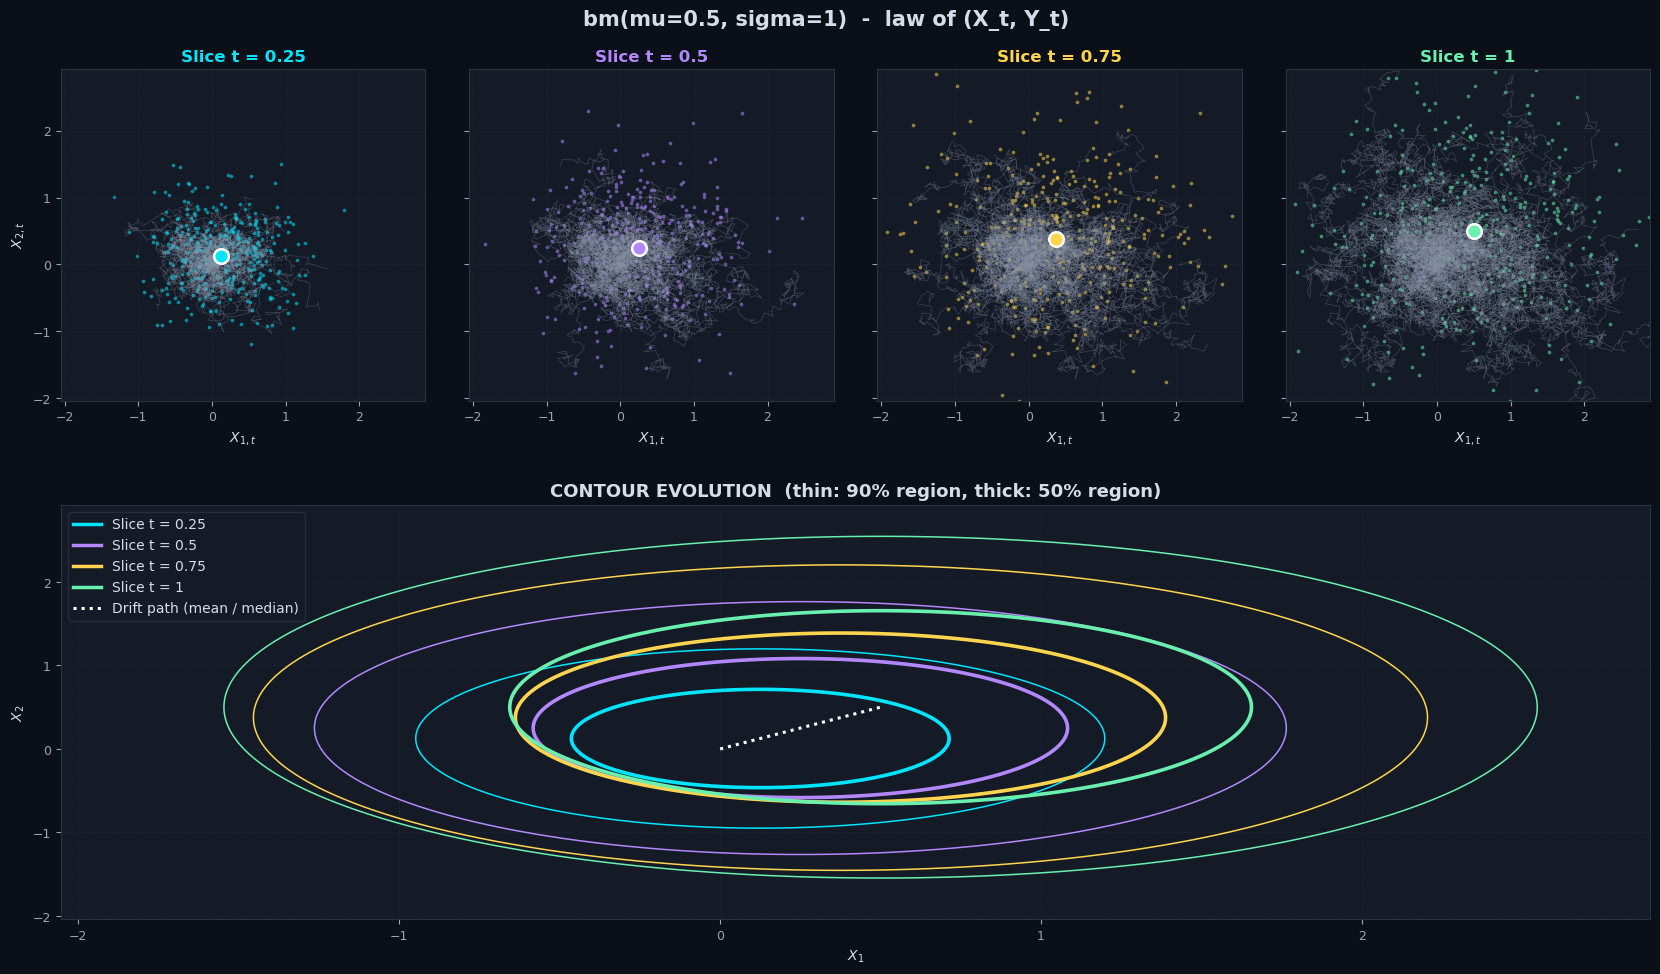

In [18]:
import radonika as rd
m1 = rd.bm(mu=0.5, sigma=1.0, seed=1) 
m1.analyze(t=4, T=1.0, n=400, n_paths=60, seed=1); 

3. **Importance Sampling & Effective Sample Size** (`ess`)

   I repeat that you see the [Process Layer](https://kalaapks.github.io/radonika_theory-dev/02_radonika/Radonika_process_layer.html) before this. When you tilt a process (via `tilt()`), toggle measures (`P`, `Q`, `Q1`, `Q2`), or run `LikelihoodRatio.summary()` / `rare_event()`, `radonika` doesn't always re-simulate new paths from scratch. Instead, it keeps the original samples $X_1, \dots, X_n$ simulated under the baseline measure $\mathbb{P}$ and assigns each sample an importance weight $w_i = \frac{d\mathbb{Q}}{d\mathbb{P}}(X_i)$ and **establishing this fact was kind of the main point of this library to begin with**. `ess(w)` in `_utils.py` measures how trustworthy those reweighted samples still are.

Let us first understand the main problem. 

Suppose we simulate $n = 10,000$ paths under $\mathbb{P}$ to estimate an expectation under $\mathbb{Q}$ : $$\mathbb{E}^\mathbb{Q}[g(X)] = \mathbb{E}^\mathbb{P}\left[g(X)\frac{d\mathbb{Q}}{d\mathbb{P}}(X)\right] \approx \frac{\sum_{i=1}^n w_i g(X_i)}{\sum_{i=1}^n w_i}$$
Ideal case: $\mathbb{P}$ and $Q$ are very close, so all weights are roughly equal ($w_1 \approx w_2 \approx \dots \approx w_n \approx 1$). Every single simulated path contributes equally, so we effectively have $10,000$ useful samples.

Degenerate case: $\mathbb{Q}$ is shifted far away from $\mathbb{P}$ (for example, after a large time $t$ or a strong Esscher tilt $\theta$). Almost all paths simulated under $\mathbb{P}$ land in regions where $\mathbb{Q}$ has near-zero probability ($w_i \approx 0$), while one lucky outlier path lands where $\mathbb{Q}$ is concentrated and gets $99.9\%$ of the total weight ($w_1 = 9999$, and $w_2 = \dots = w_n \approx 0.0001$).Even though you simulated $10,000$ paths, your estimate is really being driven by just 1 path—meaning huge Monte Carlo variance!

In `_utils.py`, `ess(w)` computes **Kish's Effective Sample Size** defined as 
$$\text{ESS} = \frac{\left(\sum_{i=1}^n w_i\right)^2}{\sum_{i=1}^n w_i^2}$$
Let's test this formula on the two extreme cases with $n = 10,000$. 
    All weights equal ($w_i = c$ for all $i$):$$\text{ESS} = \frac{(n \cdot c)^2}{n \cdot c^2} = \frac{n^2 c^2}{n c^2} = n = 10,000$$All $10,000$ samples are effective.
    One weight dominates ($w_1 = 1$, and $w_2 = \dots = w_n = 0$):$$\text{ESS} = \frac{1^2}{1^2 + 0 + \dots + 0} = 1$$Only $1$ sample is effective!In general, $1 \le \text{ESS} \le n$, and it is invariant to scaling the weights (multiplying all $w_i$ by a constant cancels out between numerator and denominator).

Let us see this in action. Compare two Brownian motions with different drifts (`mu=1` vs `mu=0`) and check "ESS" at $t = 0.2$ (close) versus $t = 5.0$ (far apart).

In [7]:
import radonika as rd

p = rd.bm(mu=1.0, sigma=1.0, seed=1)
q = rd.bm(mu=0.0, sigma=1.0, seed=1)
z = rd.lr(p, q)    #we will see "lr()" next

z.summary(t=0.2)   # High ESS: P and Q still overlap heavily
z.summary(t=5.0)   # Low ESS: almost all 8,000 paths have collapsed weights

Likelihood ratio (girsanov, path-level) at t=0.2
               t: 0.2
            E[Z]: 0.98488
             ESS: 5387.6
               n: 8000
     KL_rate_est: 1.0735
   KL_rate_exact: 1
Likelihood ratio (girsanov, path-level) at t=5
               t: 5
            E[Z]: 0.68475
             ESS: 41.172
               n: 8000
     KL_rate_est: 1.0147
   KL_rate_exact: 1


{'t': 5.0,
 'E[Z]': np.float64(0.6847460428563107),
 'ESS': 41.17163308528412,
 'n': 8000,
 'KL_rate_est': np.float64(1.0146920846220102),
 'KL_rate_exact': np.float64(1.0)}

Ofcourse ignore `KL_` outputs, we haven't seen them yet. But 
     
     ESS: 5387 
       n: 8000
tells us that among 8000 paths, only 5387 were meaningful, ie, "Out of 8,000 simulated paths, the weights are concentrated enough that our reweighted estimate has the statistical accuracy of only 412 independent draws from $\mathbb{Q}$". 

In [6]:
import radonika as rd

m = rd.bm(mu=1.0, sigma=1.0, seed=1)
X = m.sample(t=2.0, n=10_000)

w_small = m.weights(t=2.0, X=X, start=(0.0, 0.0), theta=-0.2)
w_large = m.weights(t=2.0, X=X, start=(0.0, 0.0), theta=-1.5)

print("Mild tilt ESS  :", rd.ess(w_small))
print("Strong tilt ESS:", rd.ess(w_large))

Mild tilt ESS  : 8540.18218303507
Strong tilt ESS: 29.039304248799986


We will also find the parameter "ESS" showing up on the top-right corner when you code
```python
import radonika as rd

m = rd.bm(mu=1.0, sigma=1.0, seed=1)
m.tilt(time_slice=15)
```
You will notice as you slide to different `theta` and some value of `t`, the the effective sample size shrinks rapidly.

4. **Absolute Continuity vs. Mutual Singularity** (`SingularMeasureError`)

   When you call `rd.lr(p, q)` in `measure.py`, you are asking for the Radon-Nikodym derivative $Z_t = \frac{d\mathbb{Q}}{d\mathbb{P}}$. Intuitively, $Z_t(\omega)$ reweights paths simulated under $\mathbb{P}$ so they follow the probability law of $\mathbb{Q}$. For $Z_t = \frac{d\mathbb{Q}}{d\mathbb{P}}$ to exist, $\mathbb{Q}$ must be absolutely continuous with respect to $\mathbb{P}$ (written $\mathbb{Q} \ll \mathbb{P}$):$$\text{Whenever } \mathbb{P}(A) = 0, \text{ we must also have } \mathbb{Q}(A) = 0$$
In words, $\mathbb{Q}$ cannot assign positive probability to events or paths that are impossible under $\mathbb{P}$ (you cannot reweight a zero probability into a non-zero probability).   At the opposite extreme, two measures $\mathbb{P}$ and $\mathbb{Q}$ are mutually singular ($\mathbb{P} \perp \mathbb{Q}$) if there exists a set of paths $A$ such that:$$\mathbb{P}(A) = 1 \quad \text{and} \quad \mathbb{Q}(A) = 0.$$
Here, $\mathbb{P}$ and $\mathbb{Q}$ live on completely disjoint sets of paths, so no density ratio $\frac{d\mathbb{Q}}{d\mathbb{P}}$ can exist. In `measure.py`, `LikelihoodRatio._classify()` catches four classic cases of mutual singularity and raises `SingularMeasureError`.

$\bullet$ The Four Singularity Checks in `LikelihoodRatio._classify()`

   **1** . Mismatched support of density fucntions. (this is understood)
   
   **2** . Different Volatilities in Diffusions (mean can be different)

   **3** . Different shapes (both a needs to be same, b can be different) of two Gamma process

   **4** . Different Scale or drift in Cauchy process

Let us investigate them one by one. First one is for `_IID`, second one is for `bm` & `stocks`, third is for "Gamma jump process" and fourth is for "Cauchy jump process". Intuitively, once we see (2), the other will follow similar ideas.

   **Different Volatilities in Diffusions**: We will see the detailed mathematical discussion but before that let us realise that this is very obvious geometrically. If we have two processes, imagine them as a bunch of paths, if they look different because they have different spread the entire idea of "recolour without changing the actual paths kinda falls apart". Write the following codes and see the difference yourself.
   ```python
    b = rd.bm(mu=0.5, sigma=1.0, seed=1)
    s = rd.stocks(mu=0.45, sigma=0.4, r=0.03, seed=1) 
    b.plot_law(start=None, time=4.0, n=60, seed=1)
    s.plot_law(start=None, time=4.0, n=60, seed=1)
   ```
 
 
   **(i)** The Setup is of two Diffusion Models ($\mathbb{P}$ vs. $\mathbb{Q}$): Suppose you are observing a continuous stochastic process $X_s$ (like a stock price or Brownian motion) over a tiny time window $[0, t]$. We have two competing probability measures for how $X_s$ behaves. Under measure $\mathbb{P}$, the diffusion matrix (volatility) is $A_{\mathbb{P}}$, with covariance $\Sigma_{\mathbb{P}} = A_{\mathbb{P}} A_{\mathbb{P}}^T$. Under measure $\mathbb{Q}$, the diffusion matrix is $A_{\mathbb{Q}}$, with covariance $\Sigma_{\mathbb{Q}} = A_{\mathbb{Q}} A_{\mathbb{Q}}^T$, where $\Sigma_{\mathbb{P}} \neq \Sigma_{\mathbb{Q}}$. In discrete time (say, daily closing prices), if a stock moves by $2\%$ on Monday, it could have come from a low-volatility regime (a rare $3\sigma$ event) or a high-volatility regime (a normal $1\sigma$ event). Because both models assign positive probability to that path, the Radon–Nikodym derivative $\frac{d\mathbb{Q}}{d\mathbb{P}}$ is well-defined.In continuous time, that overlap completely vanishes.
   
   **(ii)** Quadratic Variation: If you chop the time interval $[0, t]$ into $n$ tiny sub-intervals of size $\Delta t = t/n$, the increment of the process is $\Delta X_k = X_{t_{k+1}} - X_{t_k}$. For a standard diffusion $dX_s = \mu_s\,ds + A\,dW_s$, the drift term scales like $\Delta t$ and the random Brownian shock scales like $\sqrt{\Delta t}$. When you square the increments and sum them up, the drift terms ($\sim (\Delta t)^2$) vanish as $n \to \infty$, while the squared Brownian shocks ($\sim (\sqrt{\Delta t})^2 = \Delta t$) accumulate cleanly without any randomness left over. $$\lim_{n \to \infty} \sum_{k=0}^{n-1} (X_{t_{k+1}} - X_{t_k})(X_{t_{k+1}} - X_{t_k})^T = A A^T t = \Sigma t \quad \text{almost surely}$$
   
The proof is not that difficult but needs *convergence* results. Notice there is no randomness on the right-hand side. Even over a microscopic interval like $[0, 0.001]$ seconds, if you sample infinitely fast, the random fluctuations average out via the Law of Large Numbers to reveal the exact deterministic number $\Sigma t$.

   **(iii)** Why This Forces Mutual Singularity ($\mathbb{P} \perp \mathbb{Q}$)??
   
   Think of the space of all possible continuous paths $\Omega$. We can define a specific measurable set of paths $E_{\mathbb{P}} \in \mathcal{F}_t$ consisting of all paths whose realized quadratic variation equals $\Sigma_{\mathbb{P}} t$:$$E_{\mathbb{P}} = \left\{ \omega \in \Omega : \langle X \rangle_t(\omega) = \Sigma_{\mathbb{P}} t \right\}$$Under measure $\mathbb{P}$, almost every sample path obeys the quadratic variation limit, so $\mathbb{P}(E_{\mathbb{P}}) = 1$.Under measure $\mathbb{Q}$, almost every sample path converges to $\Sigma_{\mathbb{Q}} t \neq \Sigma_{\mathbb{P}} t$, so $\mathbb{Q}(E_{\mathbb{P}}) = 0$.Because $\mathbb{P}$ and $\mathbb{Q}$ concentrate $100\%$ of their probability mass on completely disjoint sets of paths, they are mutually singular ($\mathbb{P} \perp \mathbb{Q}$). You cannot compute a likelihood ratio $\frac{d\mathbb{Q}}{d\mathbb{P}}$ because $\mathbb{Q} \not\ll \mathbb{P}$.
   
   **(iv)** Connection to Girsanov's Theorem: Now this is why Girsanov’s Theorem, that governs switching between the physical measure $\mathbb{P}$ and the risk-neutral measure $\mathbb{Q}$, only allows you to change the drift ($\mu_{\mathbb{P}} \to \mu_{\mathbb{Q}}$), while forcing the diffusion covariance ($\Sigma_{\mathbb{P}} = \Sigma_{\mathbb{Q}}$) to remain invariant:Changing drift shifts the mean of the increments ($\sim \Delta t$), which is buried inside the much larger $\sqrt{\Delta t}$ noise at microscopic scales. A single path cannot distinguish $\mu_{\mathbb{P}}$ from $\mu_{\mathbb{Q}}$ with certainty, so $\mathbb{P}$ and $\mathbb{Q}$ remain equivalent ($\mathbb{P} \sim \mathbb{Q}$).Changing volatility alters the macroscopic "roughness" ($\langle X \rangle_t$) of the path itself, making the two probability measures instantly distinguishable with probability $1$.
   
Note: Even if $A_{\mathbb{P}} \neq A_{\mathbb{Q}}$ as matrices—for instance, via an orthogonal rotation $A_{\mathbb{Q}} = A_{\mathbb{P}} U$ where $U U^T = I$—what determines the law of $X$ is the covariance $\Sigma = A A^T$. Whenever $\Sigma_{\mathbb{P}} \neq \Sigma_{\mathbb{Q}}$, `LikelihoodRatio._classify()` immediately raises `SingularMeasureError`. This takes us back to the geometric argument we gave to begin with. Upto rotation the bunch of paths should look similar.

We will skip the in-depth mathematical justification for the next two since over continuous time they have infinite-jump-activity. So we have to get into Lévy measure.

**Different shapes of two Gamma process**: We will skip the mathematical discussion since the geometric reasoning is similar to before. For a Gamma process $X_t$,
$$\Delta X_t = X_{t+\Delta t} - X_t \sim \text{Gamma}(a\,\Delta t, \, b)$$
$a > 0$ (Shape rate): Controls the arrival frequency of jumps per unit time.

$b > 0$ (Rate / inverse scale parameter): Controls the typical size of those jumps (mean jump size scales with $1/b$).

Now suppose we have two competing models on path space $(\Omega, \mathcal{F}_t)$:Under $\mathbb{P}$, $X_t$ is a Gamma process with parameters $(a_{\mathbb{P}}, b_{\mathbb{P}})$.Under $\mathbb{Q}$, $X_t$ is a Gamma process with parameters $(a_{\mathbb{Q}}, b_{\mathbb{Q}})$. Then $a_{\mathbb{P}} \neq a_{\mathbb{Q}}$ forces $\mathbb{P} \perp \mathbb{Q}$. Rate $b$ can be different however. That justification needs much more in-depth measure theoretic argument.

**Different Scale or drift in Cauchy process**

A Cauchy process $X_t$ is a symmetric, pure-jump $1$-stable Lévy process ($\alpha = 1$). Over any time increment $\Delta t$, its increment follows a Cauchy distribution.$$\Delta X_t = X_{t+\Delta t} - X_t \sim \text{Cauchy}(\text{loc} = \mu\,\Delta t, \; \text{scale} = \gamma\,\Delta t)$$ 

$\gamma > 0$ (scale): Controls the spread / jump intensity of the process.

$\mu \in \mathbb{R}$ (loc / drift): Shifts the center linearly in time ($\mu t$).

Suppose we compare two Cauchy process models on $(\Omega, \mathcal{F}_t)$. Under $\mathbb{P}$, $X_t$ has parameters $(\mu_{\mathbb{P}}, \gamma_{\mathbb{P}})$. Under $\mathbb{Q}$, $X_t$ has parameters $(\mu_{\mathbb{Q}}, \gamma_{\mathbb{Q}})$. Unlike Brownian motion (where you can change drift $\mu$) or a Gamma process (where you can change rate $b$), if either $\gamma_{\mathbb{P}} \neq \gamma_{\mathbb{Q}}$ or $\mu_{\mathbb{P}} \neq \mu_{\mathbb{Q}}$, then $\mathbb{P} \perp \mathbb{Q}$.

Write the following to see the error:
```python
import radonika as rd

# Fails: different volatilities (sigma=1 vs sigma=2)
rd.lr(rd.bm(0, 1), rd.bm(0, 2))
```

5. **Multivariate Girsanov's Theorem** (`_logZ` for `bm` and `stocks`)

   Recall in previous section **1.2.1**, topic 6 (Radon-Nikodym Reweighting) we saw the following form already. We invert the linear relation  $Y_t = m_{\mathbb{P}} t + A W_t$ to recover the exact driving Brownian motion $\{W_t\}_t$
$$W_t = A^{-1}(Y_t - m_{\mathbb{P}} t)$$
In code: `W = np.linalg.solve(A, (Y - mp * times)... )`

Under $\mathbb{Q}$, the same paths $Y_t$ must appear to have drift $m_{\mathbb{Q}}$ instead of $m_{\mathbb{P}}$:$$Y_t = m_{\mathbb{P}} t + A W_t = m_{\mathbb{Q}} t + A \widetilde{W}_t$$ Rearranging gives the shifted process $\widetilde{W}_t$:$$\widetilde{W}_t = W_t + A^{-1}(m_{\mathbb{P}} - m_{\mathbb{Q}}) t = W_t + \theta t$$
where $\theta = A^{-1}(m_{\mathbb{P}} - m_{\mathbb{Q}}) \in \mathbb{R}^2$ is the market price of risk (or Girsanov kernel) vector (`th = np.linalg.solve(A, mp - mq)`).   By Girsanov's Theorem, $\widetilde{W}_t = W_t + \theta t$ becomes a standard 2-D Brownian motion under $\mathbb{Q}$ if we weight $\mathbb{P}$ by the Doléans-Dade exponential martingale:$$Z_t = \frac{d\mathbb{Q}}{d\mathbb{P}}\Big\vert{}_{\mathcal{F}_t} = \exp\left(-\theta^T W_t - \frac{1}{2}\Vert{}\theta\Vert{}^2 t\right)$$

What is the point???

In `process.py`, we saw 2D processes like `bm` or `stocks` where a state at time $t$ is a pair of numbers $(X_t, Y_t) \in \mathbb{R}^2$.   When you compare two measures $\mathbb{P}$ and $\mathbb{Q}$, the Radon-Nikodym derivative $Z_t = \frac{d\mathbb{Q}}{d\mathbb{P}}\big\vert{}_{\mathcal{F}_t}$ is not a static number—as time $t$ moves forward and a path $X_t$ unfolds under $\mathbb{P}$, $Z_t$ evolves randomly over time. In fact, $Z_t$ is itself a 1D stochastic process ($Z_t \in \mathbb{R}^1$)!   `LikelihoodRatio` in `measure.py` will literally inherit from `Process` with `dim = 1` (`class LikelihoodRatio(Process): dim = 1`). That will mean we can simulate $Z_t$, slice it at time $t$, and plot its law just like any other process!   

What will we do???

We will define something called `lr(p ,q)`, `summary(time)` and `plot_law()`. Let's see them one by one.

Now `lr(p, q)` is just a call which will return `LikelihoodRatio(p, q)` object. When you initialize it:   
   **step 1** Validates the pair (`_classify`): It checks whether $\mathbb{Q} \ll \mathbb{P}$ (raising SingularMeasureError if they have different volatilities, mismatched supports, etc.) and tags what formula it will use (`"girsanov"`, `"poisson"`, `"gamma"`, `"iid"`, or `"marginal"`).   
   **step 2** Defines how to simulate $Z_t$ (`simulate`): Whenever `z.simulate(n, times, ...)` is called it simulates $n$ paths of the first process `p` under $\mathbb{P}$ as `X = self.p.simulate(...)` and then it plugs those $\mathbb{P}$-paths into `_logZ` (the Girsanov/jump/i.i.d. formula) and exponentiates (`np.exp(L)`) to get the trajectory of $Z_t$ along each path.   
   
So `z` is a 1D process representing "the value of the likelihood ratio $Z_t$ as paths evolve under $\mathbb{P}$". 

We will also define something called `summary(t=)` and it will run a quick Monte Carlo health check on $Z_t$ at time $t$ (simulating $n = 8000$ paths of $Z_t$ under $\mathbb{P}$) and prints four numbers:

$\bullet$ `E[Z]`~ $\mathbb{E^{P}}[Z]$ and it should be around $1.0$ because
$$\mathbb{E}^{\mathbb{P}}[Z_t] = \int \frac{d\mathbb{Q}}{d\mathbb{P}} d\mathbb{P} = \int d\mathbb{Q} = 1$$

$\bullet$ `ESS`(Effective Sample Size) as before checks how many of those $8000$ paths are meaningful.

$\bullet$ `KL_rate_est` estimates the Kullback-Leibler divergence rate between $\mathbb{P}$ and $\mathbb{Q}$ (which we will cover next) and is given by the formuale
$$-\frac{1}{t}\mathbb{E}^{\mathbb{P}}[\log Z_t]$$

$\bullet$ `KL_rate_exact` prints the exact analytical KL rate so you can compare your Monte Carlo estimate against theory for Girsanov pairs and is given by the formuale $\frac{1}{2}\Vert{}\theta\Vert{}^2$.

Lastly, `plot_law()` will create the plot of $\{Z_t\}_t$'s density evolution over time on left and the paths on right.

Run the following code to see the result.

```python
import radonika as rd

z = rd.lr(rd.bm(mu=1.0, sigma=1.0, seed=1), rd.bm(mu=0.0, sigma=1.0, seed=1))
z.summary(t=1.0)
z.plot_law(time_slice=45, n=70)
```

In [10]:
import radonika as rd

z = rd.lr(rd.bm(mu=1.0, sigma=1.0, seed=1), rd.bm(mu=0.0, sigma=1.0, seed=1))
z.summary(t=1.0)

Likelihood ratio (girsanov, path-level) at t=1
               t: 1
            E[Z]: 0.95931
             ESS: 1274.3
               n: 8000
     KL_rate_est: 1.0329
   KL_rate_exact: 1


{'t': 1.0,
 'E[Z]': np.float64(0.9593090270032537),
 'ESS': 1274.2513802981607,
 'n': 8000,
 'KL_rate_est': np.float64(1.0328524999459947),
 'KL_rate_exact': np.float64(1.0)}

6. **Likelihood Ratios for I.I.D. & Jump Processes** (`_logZ` for `iid`, `poisson`, `gamma_process`)

   We used Multivariate Girsanov for finding likelihood ratios for `bm` and `stocks` since both were a type of `bm` (for stocks we have to take a log and then it is `bm`). We will do it for `_IID` and Jumps processes now.

#### (i) I.I.D. Sequences (`kind == "iid"`)
For an i.i.d. process (`normal`, `cauchy`, `exponential`, etc.), the state $X_{t_k} \in \mathbb{R}^2$ at each discrete step $t_1, t_2, \dots, t_m$ is drawn independently from a density $p(x)$ under $\mathbb{P}$ or $q(x)$ under $\mathbb{Q}$.

* Because steps are independent, the joint density of a path $(X_{t_1}, \dots, X_{t_m})$ is simply the product of the individual step densities:
  $$Z_{t_m} = \frac{d\mathbb{Q}}{d\mathbb{P}}(X_{t_1}, \dots, X_{t_m}) = \prod_{j=1}^{m} \frac{q(X_{t_j})}{p(X_{t_j})}$$
* Taking the logarithm turns this product into a cumulative sum (with $Z_0 = 1 \implies \log Z_0 = 0$):
  $$\log Z_{t_m} = \sum_{j=1}^{m} \left(\log q(X_{t_j}) - \log p(X_{t_j})\right)$$
* In `_logZ`, `self.q.logpdf(X[:, 1:, :]) - self.p.logpdf(X[:, 1:, :])` computes the per-step log-density ratio across both coordinates, and `np.cumsum(..., axis=1)` accumulates it over time. *(Note: Because products of independent ratios decay exponentially fast on almost all paths while rare paths spike, `LikelihoodRatio.plot_law()` defaults to `log=True` for `"iid"` processes!)*


#### (ii) Poisson Processes (`kind == "poisson"`)
Suppose under $\mathbb{P}$, $N_t = X_t - X_0 \in \mathbb{Z}_{\ge 0}^2$ is a 2-D Poisson process with intensity vector $\lambda_{\mathbb{P}} = (\lambda_{\mathbb{P},1}, \lambda_{\mathbb{P},2})$, and under $\mathbb{Q}$ it has intensity $\lambda_{\mathbb{Q}} = (\lambda_{\mathbb{Q},1}, \lambda_{\mathbb{Q},2})$.

* For a single 1-D Poisson process over $[0, t]$, the probability of observing $k$ jumps is $\frac{(\lambda t)^k e^{-\lambda t}}{k!}$. Notice that the combinatorial factor $k!$ (and the exact jump arrival times) is identical under both $\mathbb{P}$ and $\mathbb{Q}$, so it cancels out in the likelihood ratio:
  $$\frac{d\mathbb{Q}}{d\mathbb{P}}\Big\vert{}_{\mathcal{F}_t} = \frac{\lambda_{\mathbb{Q}}^{N_t} e^{-\lambda_{\mathbb{Q}} t}}{\lambda_{\mathbb{P}}^{N_t} e^{-\lambda_{\mathbb{P}} t}} = \left(\frac{\lambda_{\mathbb{Q}}}{\lambda_{\mathbb{P}}}\right)^{N_t} \exp\left(-(\lambda_{\mathbb{Q}} - \lambda_{\mathbb{P}})\,t\right)$$
* Summing the logs across the two independent coordinates gives the exact formula in `_logZ`:
  $$\log Z_t = \sum_{k=1}^{2} N_{k,t} \log\left(\frac{\lambda_{\mathbb{Q},k}}{\lambda_{\mathbb{P},k}}\right) - \sum_{k=1}^{2} (\lambda_{\mathbb{Q},k} - \lambda_{\mathbb{P},k})\,t$$
  Notice that $\log Z_t$ depends on the path **only through the total jump count $N_t$** at time $t$ (the jump count is a sufficient statistic).

#### (iii) Gamma Processes (`kind == "gamma"`)
A Gamma subordinator $N_t = X_t - X_0$ has independent increments $N_t \sim \text{Gamma}(a t, b)$. As established in Topic 4 (Sato's theorem), $\mathbb{Q} \ll \mathbb{P}$ requires both processes to share the exact same shape rate $a = a_{\mathbb{P}} = a_{\mathbb{Q}}$, while the rate parameter $b$ can change from $b_{\mathbb{P}}$ to $b_{\mathbb{Q}}$.

* In 1-D, the density of $N_t = x > 0$ under $\text{Gamma}(at, b)$ is:
  $$f(x; at, b) = \frac{b^{at}}{\Gamma(at)}\, x^{at - 1} e^{-bx}$$
* Because $a$ is identical under $\mathbb{P}$ and $\mathbb{Q}$, the $\Gamma(at)$ and $x^{at - 1}$ terms cancel completely when taking the ratio:
  $$\frac{d\mathbb{Q}}{d\mathbb{P}}\Big\vert{}_{\mathcal{F}_t} = \frac{b_{\mathbb{Q}}^{at} e^{-b_{\mathbb{Q}} N_t}}{b_{\mathbb{P}}^{at} e^{-b_{\mathbb{P}} N_t}} = \left(\frac{b_{\mathbb{Q}}}{b_{\mathbb{P}}}\right)^{at} \exp\left(-(b_{\mathbb{Q}} - b_{\mathbb{P}}) N_t\right)$$
* Taking the logarithm and summing across both coordinates yields the exact expression in `_logZ`:
  $$\log Z_t = \sum_{k=1}^{2} a_k \log\left(\frac{b_{\mathbb{Q},k}}{b_{\mathbb{P},k}}\right) t - \sum_{k=1}^{2} (b_{\mathbb{Q},k} - b_{\mathbb{P},k}) N_{k,t}$$
  Just like the Poisson process, changing the rate $b$ corresponds to an exponential tilt of the total process height $N_t$!


```python
import radonika as rd

z = rd.lr(rd.poisson(rate=1.0, seed=1), rd.poisson(rate=2.5, seed=1))
z.summary(t=2.0)
z.plot_law(time_slice=15, n=25)


7. **Marginal Projections & KL Divergence Rate** (`marginal` kind & `summary`)

   For `bm`, `stocks`, `iid`, `poisson`, and `gamma_process`, we know the exact likelihood ratio $Z_t = \left.\frac{d\mathbb{Q}}{d\mathbb{P}}\right\vert{}_{\mathcal{F}_t}$ of the entire path up to time $t$. What if we compare two processes from different families that both have closed-form time-$t$ marginal densities $p_t(x)$ and $q_t(x)$. For example, comparing a Brownian motion (`bm`) against a Student-$t$ process (`student_t`) or a `normal` i.i.d. process against a `laplace` process? Instead of comparing the whole movie (the entire path from $0$ to $t$), measure.py falls back to comparing only the single photograph at time $t$.
   
   $\bullet$ In `LikelihoodRatio._classify()`, if the pair doesn't match the exact path-level families, it tests whether `p.pdf(...)` and `q.pdf(...)` both return valid values. If they do, it sets `self.kind = "marginal"` and `self.exact = False`.

   $\bullet$ Instead of the full path-level ratio $Z_t$, `_logZ` computes the time-$t$ marginal density ratio:$$Z_t^{\text{marg}} = \frac{q_t(X_t)}{p_t(X_t)} \quad \Longrightarrow \quad \log Z_t^{\text{marg}} = \log q_t(X_t) - \log p_t(X_t)$$

Why is this mathematically meaningful?
By the tower property of conditional expectation, the marginal density ratio is the orthogonal projection (conditional expectation) of the true path-level Radon-Nikodym derivative $Z_t$ onto the information at time $t$ alone ($\sigma(X_t)$):$$\mathbb{E}^{\mathbb{P}}\!\left[Z_t \,\middle|\, X_t = x\right] = \frac{q_t(x)}{p_t(x)}$$What it preserves: At any single fixed slice $t$, reweighting samples $X_t$ from $\mathbb{P}$ by $q_t(X_t)/p_t(X_t)$ produces the exact time-$t$ marginal distribution of $\mathbb{Q}$ (so $\mathbb{E}^{\mathbb{P}}[Z_t^{\text{marg}}] = 1$ still holds at every $t$).

What it loses: Because it ignores how the path got to $X_t$, $Z_t^{\text{marg}}$ is not a martingale over time (unlike the true path-level $Z_t$), which is why `summary()` explicitly labels whether the output is `path-level` or `marginal` `E[Z|X_t]`.

**Def (Kullback-Leibler (KL) Divergence Rate) :**  At time $t$, let $\mathbb{P}_t$ and $\mathbb{Q}_t$ be the laws of the process on $[0, t]$. The KL divergence from $\mathbb{Q}_t$ to $\mathbb{P}_t$ is:$$D_{\text{KL}}(\mathbb{P}_t \,\Vert{}\, \mathbb{Q}_t) = \mathbb{E}^{\mathbb{P}}\!\left[\log \frac{d\mathbb{P}_t}{d\mathbb{Q}_t}\right]$$Since $Z_t = \frac{d\mathbb{Q}_t}{d\mathbb{P}_t}$, its reciprocal is $\frac{d\mathbb{P}_t}{d\mathbb{Q}_t} = \frac{1}{Z_t} = Z_t^{-1}$. Taking the logarithm flips the sign:$$D_{\text{KL}}(\mathbb{P}_t \,\|\, \mathbb{Q}_t) = \mathbb{E}^{\mathbb{P}}\!\left[\log(Z_t^{-1})\right] = -\mathbb{E}^{\mathbb{P}}[\log Z_t]$$
Now we divide by $t$ to get the rate:
$$\text{KL rate} = \frac{1}{t}\, D_{\text{KL}}(\mathbb{P}_t \,\|\, \mathbb{Q}_t) = -\frac{1}{t}\,\mathbb{E}^{\mathbb{P}}[\log Z_t]$$

In `LikelihoodRatio.summary(t=1.0)`, `radonika` measures how fast the two probability laws $\mathbb{P}$ and $\mathbb{Q}$ separate over time using the Kullback-Leibler (KL) divergence. In `summary()`, this is estimated via Monte Carlo as `kl = -np.mean(np.log(np.maximum(Z, 1e-300))) / t`.

For two Gaussian diffusions (`bm` or `stocks`) with market price of risk $\theta = A^{-1}(m_{\mathbb{P}} - m_{\mathbb{Q}})$, we know from Topic 5 that:$$\log Z_t = -\theta^T W_t - \frac{1}{2}\Vert{}\theta\Vert{}^2 t$$Since $W_t$ is a standard Brownian motion under $\mathbb{P}$, $\mathbb{E}^{\mathbb{P}}[W_t] = 0$. Taking $-\frac{1}{t}\mathbb{E}^{\mathbb{P}}[\cdot]$ gives:$$\text{KL rate} = -\frac{1}{t}\left(-\theta^T \underbrace{\mathbb{E}^{\mathbb{P}}[W_t]}_{0} - \frac{1}{2}\Vert{}\theta\Vert{}^2 t\right) = \frac{1}{2}\Vert{}\theta\Vert{}^2$$

8. **Esscher Importance Sampling & Saddlepoint Centering** (`rare_event`)

   This brings together `process.py`, `_utils.py`, and `measure.py` to solve a classic computational problem of estimating the probability of an extreme rare event, such as $p = \mathbb{P}(X^1_T > K)$ when $K$ is many standard deviations out in the tail (e.g., $p \approx 10^{-8}$).
   
(i) Why Naive Monte Carlo Fails? Suppose we want to estimate $p = \mathbb{P}(X^1_T > K)$ using $N = 100,000$ standard simulated paths under the original measure $\mathbb{P}$, then
$$\hat{p}_{\text{naive}} = \frac{1}{N} \sum_{i=1}^N \mathbf{1}_{\{X^1_{i,T} > K\}}$$ If the true probability is $p = 10^{-7}$ and we simulate $N = 10^5$ paths, almost every single run will produce zero hits ($\hat{p}_{\text{naive}} = 0$), and even when one path hits, the relative standard error is massive:$$\text{Relative Error} = \frac{\text{SE}(\hat{p})}{p} = \frac{\sqrt{p(1-p)/N}}{p} \approx \frac{1}{\sqrt{N p}} \to \infty \quad \text{as } p \to 0.$$
(ii) The Importance Sampling Change of Measure: Instead of simulating under $\mathbb{P}$ (where $X^1_T > K$ almost never happens), we switch to an Esscher-tilted measure $\mathbb{Q}_\theta$ (via `m.esscher(th)`) where the rare event becomes completely ordinary!

Using the Radon-Nikodym derivative $Z_T = \frac{d\mathbb{Q}_\theta}{d\mathbb{P}}\big\vert{}_{\mathcal{F}_T}$, we rewrite the tail probability as an expectation under $\mathbb{Q}_\theta$:$$p = \mathbb{E}^{\mathbb{P}}\!\left[\mathbf{1}_{\{X^1_T > K\}}\right] = \mathbb{E}^{\mathbb{Q}_\theta}\!\left[\mathbf{1}_{\{X^1_T > K\}} \frac{d\mathbb{P}}{d\mathbb{Q}_\theta}\right] = \mathbb{E}^{\mathbb{Q}_\theta}\!\left[\mathbf{1}_{\{X^1_T > K\}} Z_T^{-1}\right]$$

From `process.py`, an Esscher tilt with parameter $\theta = (\theta_1, 0)^T$ defines the likelihood ratio via the Lévy state $Y_T = \text{levy\_state}(X_T, \text{start})$ and the cumulant generating function $\kappa(\theta) = \frac{1}{T}\log \mathbb{E}^{\mathbb{P}}[e^{\theta \cdot Y_T}]$:
$$Z_T = \exp\left(\theta \cdot Y_T - T\,\kappa(\theta)\right)$$
Taking the reciprocal $w_i = Z_{i,T}^{-1}$ gives the exact importance weight in `rare_event()`:
   $$w_i = \exp\left(-\theta \cdot Y_{i,T} + T\,\kappa(\theta)\right)$$
So our unbiased Importance Sampling estimator is:
   $$\hat{p}_{\text{IS}} = \frac{1}{N} \sum_{i=1}^N \mathbf{1}_{\{X^1_{i,T} > K\}} \exp\left(-\theta \cdot Y_{i,T} + T\,\kappa(\theta)\right)$$

We optimize this now and fine the best $\theta_1$. By large deviations theory (and the saddlepoint approximation), the variance is minimized when the mean of the tilted distribution $\mathbb{Q}_\theta$ sits right at the threshold $K$:
$$\mathbb{E}^{\mathbb{Q}_\theta}[X^1_T] = K$$Under $\mathbb{Q}_\theta$, roughly 50% of all simulated paths will now exceed $K$, and every single hit carries a tiny, nearly uniform weight $w_i \approx p$!

  $\bullet$ In `rare_event()` (`measure.py`): Bracketing & Root-Finding (brentq): It defines `mean_at(th) = m.esscher([th, 0]).marginal(T, s, 0).mean() - K`, expands a bracket `[a, b]` inside `m.theta_domain()`, and uses Brent's root-finding algorithm (`scipy.optimize.brentq`) to solve $\mathbb{E}^{\mathbb{Q}_\theta}[X^1_T] - K = 0$ for $\theta_1$.   
  
  $\bullet$ Comparison & Variance Reduction: It simulates $N = 100,000$ paths under both $\mathbb{P}$ and $\mathbb{Q}_\theta$, computes the running means and standard errors (`mn`, `sn` vs `mi`, `si`), checks the `ESS` of the hitting weights (`ess(w[XQ[:, 0] > K])`), compares against the exact survival function `m.marginal(T, s, 0).sf(K)`, and reports the variance reduction factor $(\text{SE}_{\text{naive}} / \text{SE}_{\text{IS}})^2$.

P(X^1_T > 3.2)  exact = 6.8714e-04   tilt theta_1 = 3.2000
  naive MC      : 7.7000e-04 +- 1.72e-04
  importance S. : 6.9180e-04 +- 8.13e-06
  variance reduction ~ x447


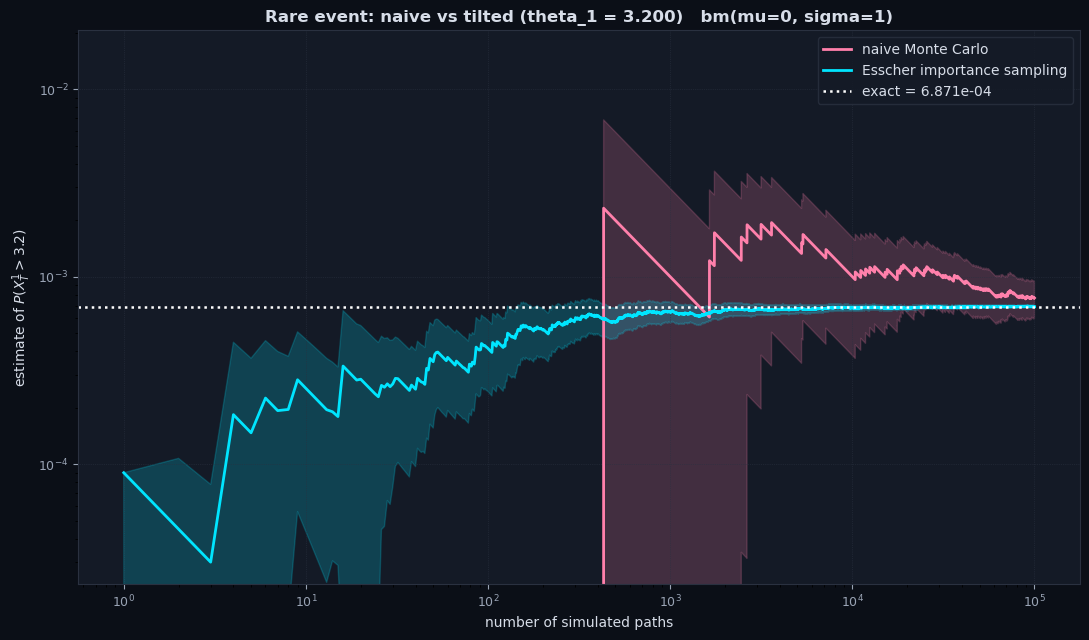

In [17]:
import radonika as rd

m = rd.bm(mu=0.0, sigma=1.0, seed=1)
res_mod = m.rare(K=3.2, T=1.0)

What we are looking at is the output of `plot_rare` for estimating the rare-event tail probability $\mathbb{P}(X^1_1 > 3.2)$ of a standard Brownian motion `bm(mu=0, sigma=1)`:

### 1. Axes & Ground Truth
* **Horizontal Axis (`number of simulated paths`):** Shows how many paths $n$ have been simulated so far, running on a **logarithmic scale** from $10^0 = 1$ path on the left up to $10^5 = 100,000$ paths on the right.
* **Vertical Axis (`estimate of P(X^1_T > 3.2)`):** Shows the running probability estimate on a **logarithmic scale** between roughly $2 \times 10^{-5}$ and $2 \times 10^{-2}$.
* **Dotted White Horizontal Line (`exact = 6.871e-04`):** The true analytical probability $1 - \Phi(3.2) \approx 0.0006871$ (about 1 in 1,455 paths).

---

### 2. The Pink Curve: Naive Monte Carlo (`naive Monte Carlo`)
* **From $n = 1$ to $n \approx 430$ paths:** The pink curve isn't visible because **zero simulated paths crossed $3.2$**—so the running estimate is $0$ (which sits below the bottom of the log axis).
* **The Vertical Spike around $n \approx 430$:** At roughly path #430, the **very first path** finally exceeds $3.2$. The estimate immediately jumps from $0$ up to $1 / 430 \approx 2.3 \times 10^{-3}$ (overestimating the true probability by more than 3×).
* **The Sawtooth Decay ($n = 430$ to $10^5$):** Every time another path fails to exceed $3.2$, the running average slopes downward smoothly as $1/n$; whenever a rare hit occurs, it jumps upward again. Even at $n = 100,000$, the pink line still sits slightly above the dotted line with a wide pink 95% confidence band around it.

---

### 3. The Cyan Curve: Esscher Importance Sampling (`Esscher importance sampling`)
* **Immediate Signal ($n = 1$ onward):** Because the Esscher tilt ($\theta_1 = 3.200$) shifts the Brownian motion's drift so its mean sits right at $3.2$, roughly **50% of every simulated path** exceeds $3.2$ from the very beginning.
* **Fast, Smooth Lock-On:** By around $n = 400$ paths—before naive Monte Carlo has even recorded a *single* hit—the cyan curve has already converged onto the dotted white exact line (`6.871e-04`).
* **Razor-Thin Confidence Band:** From $n = 10^3$ to $10^5$, the cyan line is completely flat on top of the white dotted line, and its shaded 95% confidence band shrinks to almost zero thickness—visually demonstrating massive variance reduction over naive simulation.

P(X^1_T > 5.2)  exact = 9.9644e-08   tilt theta_1 = 5.2000
  naive MC      : 0.0000e+00 +- 0.00e+00
  importance S. : 1.0058e-07 +- 1.51e-09


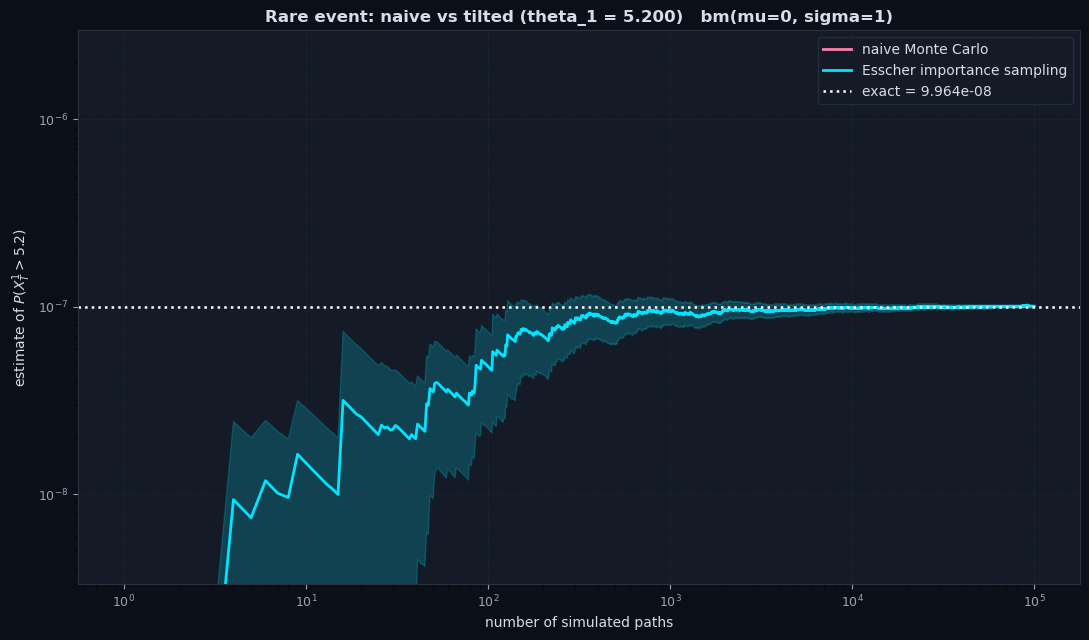

In [12]:
import radonika as rd

m = rd.bm(mu=0.0, sigma=1.0, seed=1)
res = m.rare(K=5.2, T=1.0)

**Discounted stock price SDE:**

<IPython.core.display.Math object>

<IPython.core.display.Math object>

P(X^1_T > 3.5)  exact = 1.8466e-05   tilt theta_1 = 13.2529
  naive MC      : 2.0000e-05 +- 2.77e-05
  importance S. : 1.8411e-05 +- 2.51e-07
  variance reduction ~ x12174


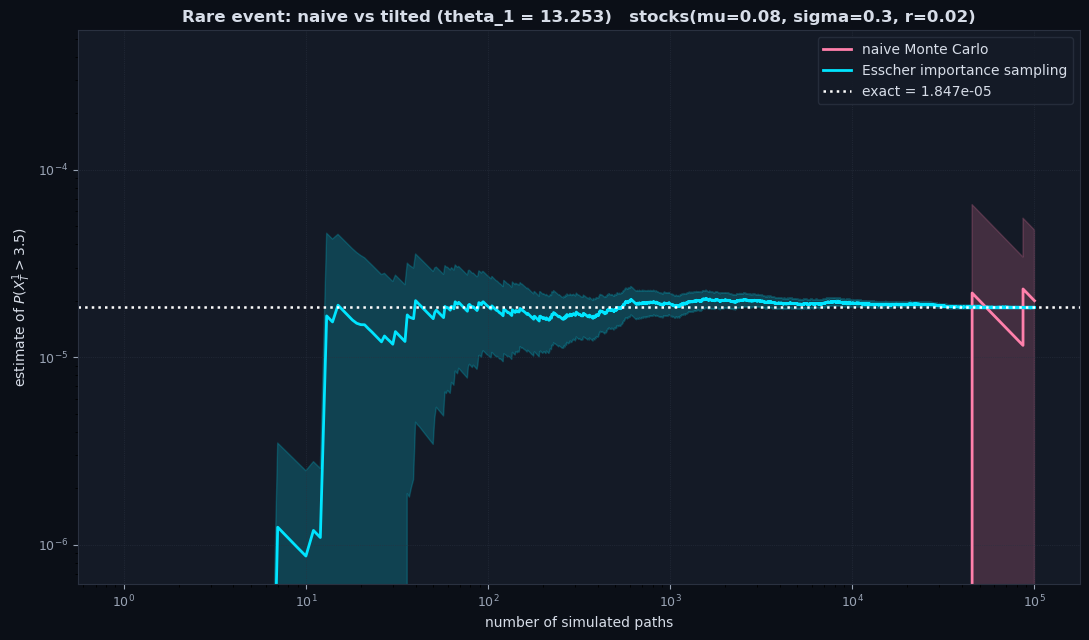

In [13]:
import radonika as rd

s = rd.stocks(mu=0.08, sigma=0.30, r=0.02, seed=42)
res_s = s.rare(K=3.5, T=1.0)

P(X^1_T > 22)  exact = 4.7891e-17   tilt theta_1 = 2.3979
  naive MC      : 0.0000e+00 +- 0.00e+00
  importance S. : 4.8200e-17 +- 9.15e-19


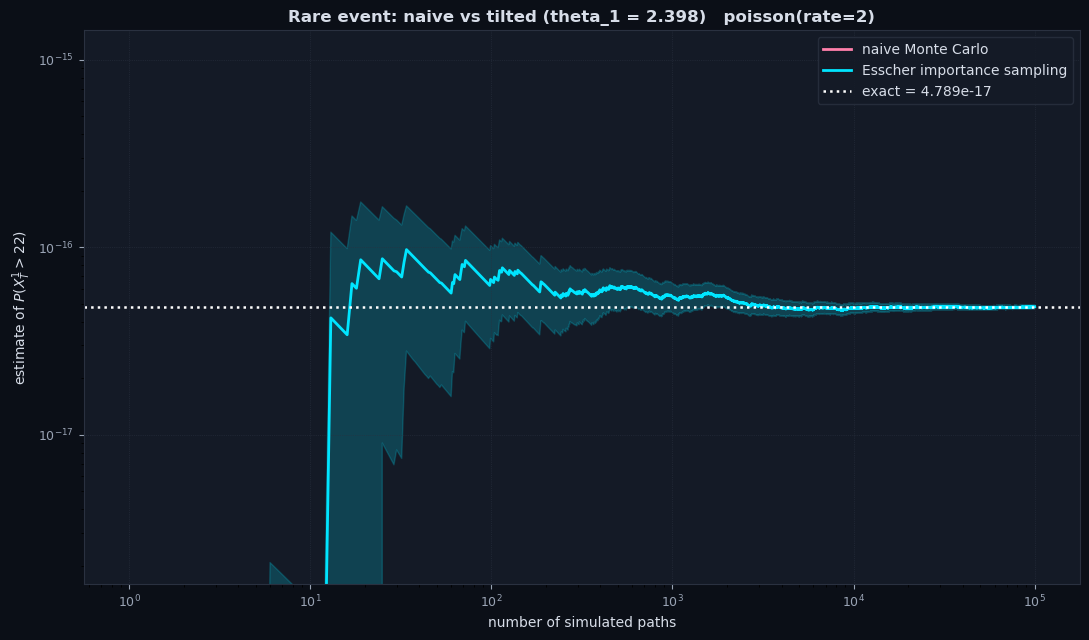

In [14]:
import radonika as rd

p = rd.poisson(rate=2.0, seed=7)
res_p = p.rare(K=22, T=1.0)

P(X^1_T > 18)  exact = 7.4884e-08   tilt theta_1 = 0.9167
  naive MC      : 0.0000e+00 +- 0.00e+00
  importance S. : 7.3347e-08 +- 1.96e-09


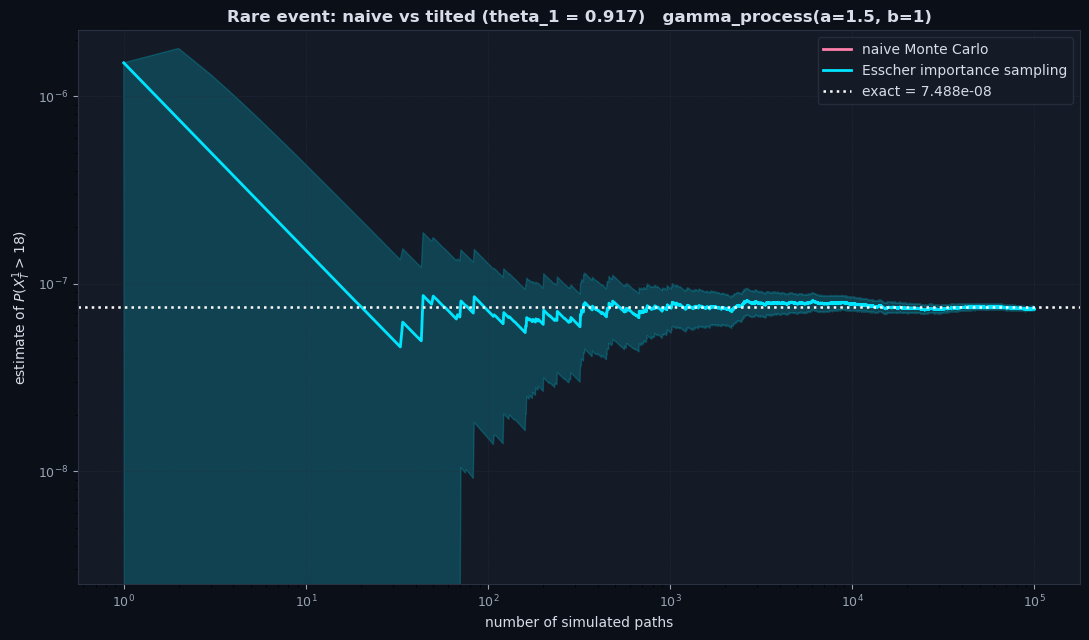

In [15]:
import radonika as rd

g = rd.gamma_process(a=1.5, b=1.0, seed=9)
res_g = g.rare(K=18.0, T=1.0)